### Libraries

In [15]:
import os
import glob
import nibabel as nb
import scipy.stats
from brainspace.mesh.mesh_io import read_surface
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.mesh.array_operations import smooth_array
import numpy as np
import seaborn as sns
import pandas as pd
import cmocean
import matplotlib.pyplot as plt
import matplotlib as mpl
from brainspace.datasets import load_mask
from matplotlib.lines import Line2D
import colormaps as clrmps
import matplotlib.cm as cm
from cmcrameri import cm

### Variables

In [16]:
# Set dataset PNI as working directory
os.chdir('/data_/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0')

# Path to MICAPIPEsurf = mask_5k !
micapipe=os.popen("echo $MICAPIPE").read()[:-1]

# Load native mid surface
inf_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.inflated.surf.gii', itype='gii')
inf_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.inflated.surf.gii', itype='gii')

mask_lh =  nb.load(micapipe + '/surfaces/fsLR-5k.R.mask.shape.gii').darrays[0].data
mask_rh =  nb.load(micapipe + '/surfaces/fsLR-5k.L.mask.shape.gii').darrays[0].data
mask_5k = np.concatenate((mask_lh, mask_rh), axis=0)

# Load fsLR 5k
f5k_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.surf.gii', itype='gii')
f5k_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.surf.gii', itype='gii')

# Load fsLR 32k
f32k_lh = read_surface(micapipe + '/surfaces/fsLR-32k.L.surf.gii', itype='gii')
f32k_rh = read_surface(micapipe + '/surfaces/fsLR-32k.R.surf.gii', itype='gii')
# Load fsLR 32k inflated
f32k_inf_lh = read_surface(micapipe + '/surfaces/fsLR-32k.L.inflated.surf.gii', itype='gii')
f32k_inf_rh = read_surface(micapipe + '/surfaces/fsLR-32k.R.inflated.surf.gii', itype='gii')
mask_32k = load_mask(join=True)

# Boolean mask
#mask_surf = mask_5k != 0
mask_surf = mask_32k != 0

### Functions

In [17]:
# Function: Smooth intensity profiles on a given surface
def smooth_surf(surf_l, surf_r, points, Mask, Kernel='uniform', Niter=3, Relax=0.35):
    '''
    Smooths intensity data on a given surface mesh using iterative smoothing.
    
    Parameters:
    -----------
    surf_l : np.array
        Left hemisphere surface connectivity.
    surf_r : np.array
        Right hemisphere surface connectivity.
    points : np.array
        Intensity profile data mapped to the surface.
    Mask : np.array
        Binary mask indicating valid regions for smoothing.
    Kernel : str, optional
        Smoothing kernel type, options: {'uniform', 'gaussian', 'inverse_distance'}.
    Niter : int, optional
        Number of smoothing iterations (default: 3).
    Relax : float, optional
        Relaxation factor controlling smoothing intensity (default: 0.35).
    
    Returns:
    --------
    sdata : np.array
        Smoothed intensity data.
    '''
    Ndim = Mask.shape[0] 
    n2dim = int(Ndim/2)
    Mask_l = Mask[:n2dim]
    Mask_r = Mask[n2dim:]
    
    sdata = np.concatenate((
        smooth_array(surf_l, points[:n2dim], kernel=Kernel, n_iter=Niter, relax=Relax, mask=Mask_l), 
        smooth_array(surf_r, points[n2dim:], kernel=Kernel, n_iter=Niter, relax=Relax, mask=Mask_r)
    ), axis=0)
    
    return sdata

# Function: Apply smoothing to intensity profiles across all depths
def smooth_intensities(int_profile):
    '''
    Applies surface smoothing to each depth of the intensity profile.
    
    Parameters:
    -----------
    int_profile : np.array
        Input intensity profiles, where rows represent different depths.
    
    Returns:
    --------
    smoothed_i : np.array
        Smoothed intensity profiles.
    '''
    smoothed_i = np.copy(int_profile)
    
    for i in range(int_profile.shape[0]):
        smoothed_i[i, :] = smooth_surf(
            f32k_inf_lh, f32k_inf_rh, int_profile[i, :], mask_surf, Niter=5, Relax=0.5, Kernel='uniform'
        )
    
    return smoothed_i

## AFD - parallel (U-fiber)

In [4]:
base_dir = '/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_noregrid'
subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083', 'PNC018_HC076',
    'PNC019_HC062', 'PNC024_HC088', 'PNC025_HC128', 'PNC022_HC132',
    'PNC026_HC130', 'PNC037_HC116', 'PNC038_HC140'
]

In [5]:
all_par_SWM = []

for subj in subject_dirs:
    subj_path = os.path.join(base_dir, subj)
    lh_path = os.path.join(subj_path, 'L_todi_PrCG-PoCG_new', 'L_fsLR32k_afd-par_results.txt')
    rh_path = os.path.join(subj_path, 'R_todi_PrCG-PoCG_new', 'R_fsLR32k_afd-par_results.txt') 
    
    try:
        lh_par = np.loadtxt(lh_path)
        rh_par = np.loadtxt(rh_path)

        # column 0 (0mm), 2 (1mm), 4 (2mm)
        par_0mm = np.concatenate((lh_par[:, 0], rh_par[:, 0]), axis=0)
        par_1mm = np.concatenate((lh_par[:, 2], rh_par[:, 2]), axis=0)
        par_2mm = np.concatenate((lh_par[:, 4], rh_par[:, 4]), axis=0)
        par_3mm = np.concatenate((lh_par[:, 6], rh_par[:, 6]), axis=0)

        # Convert -1 to NaN for missing values
        par_0mm[par_0mm == -1] = np.nan
        par_1mm[par_1mm == -1] = np.nan
        par_2mm[par_2mm == -1] = np.nan
        par_3mm[par_3mm == -1] = np.nan

        par_SWM = np.vstack([par_0mm, par_1mm, par_2mm, par_3mm])  # shape: (3, vertices)
        
        all_par_SWM.append(par_SWM)
    except Exception as e:
        print(f"Error loading subject {subj}: {e}")

# shape: (n_subjects, 3, vertices)
all_par_SWM = np.stack(all_par_SWM, axis=0)
mean_par_SWM = np.nanmean(all_par_SWM, axis=0)  # shape: (3, vertices)

/tmp/ipykernel_23193/2428719446.py:32: RuntimeWarning: Mean of empty slice
  mean_par_SWM = np.nanmean(all_par_SWM, axis=0)  # shape: (3, vertices)


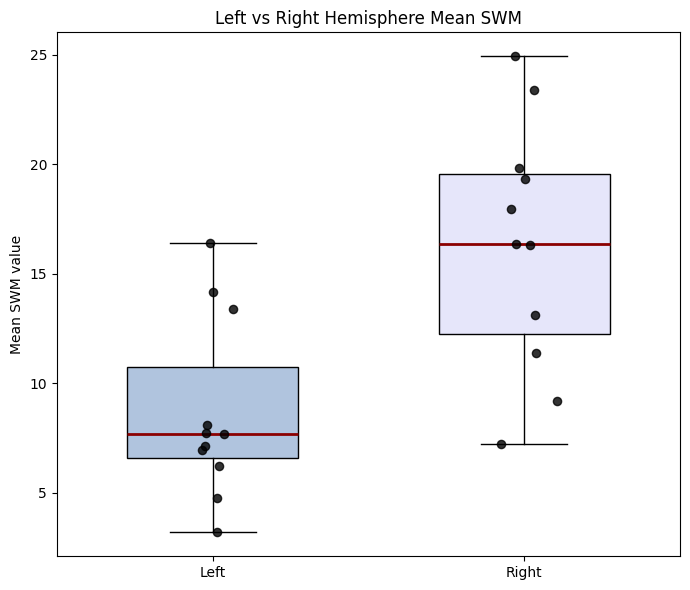

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Remove nan, 0, and -1 values
# ---------------------------------------
data = all_par_SWM.astype(float).copy()
invalid_mask = (np.isnan(data) | (data == 0) | (data == -1))
data[invalid_mask] = np.nan

# ---------------------------------------
# 2. Split left / right hemisphere
# Assumes vertices are ordered:
# left hemisphere first, right hemisphere second
# ---------------------------------------
n_vertices = data.shape[2]
half = n_vertices // 2

left_data  = data[:, :, :half]
right_data = data[:, :, half:]

# ---------------------------------------
# 3. Compute subject-wise mean
# ---------------------------------------
#left_means  = np.nanmean(left_data, axis=(1, 2))
left_means  = np.nanmean(left_data[:,0,:], axis=1)
right_means = np.nanmean(right_data, axis=(1, 2))

# ---------------------------------------
# 4. Create box-whisker plot
# ---------------------------------------
plt.figure(figsize=(7, 6))

bp = plt.boxplot(
    [left_means, right_means],
    patch_artist=True,
    widths=0.55,
    labels=["Left", "Right"],
    boxprops=dict(edgecolor='black'),
    medianprops=dict(color='darkred', linewidth=2),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    flierprops=dict(marker='o', markersize=6, markerfacecolor='gray')
)

# Fill box colors
bp['boxes'][0].set_facecolor('lightsteelblue')
bp['boxes'][1].set_facecolor('lavender')

# Overlay individual subject values
x1 = np.random.normal(1, 0.04, size=len(left_means))
x2 = np.random.normal(2, 0.04, size=len(right_means))

plt.scatter(x1, left_means, color='black', s=35, zorder=3, alpha=0.8)
plt.scatter(x2, right_means, color='black', s=35, zorder=3, alpha=0.8)

plt.ylabel("Mean SWM value")
plt.title("Left vs Right Hemisphere Mean SWM")
plt.tight_layout()
plt.show()

Original n: 511501
Trimmed n : 505766
Lower cutoff: 0.0
Upper cutoff: 0.0
Original mean: 0.107017391792976
Trimmed mean : 0.0


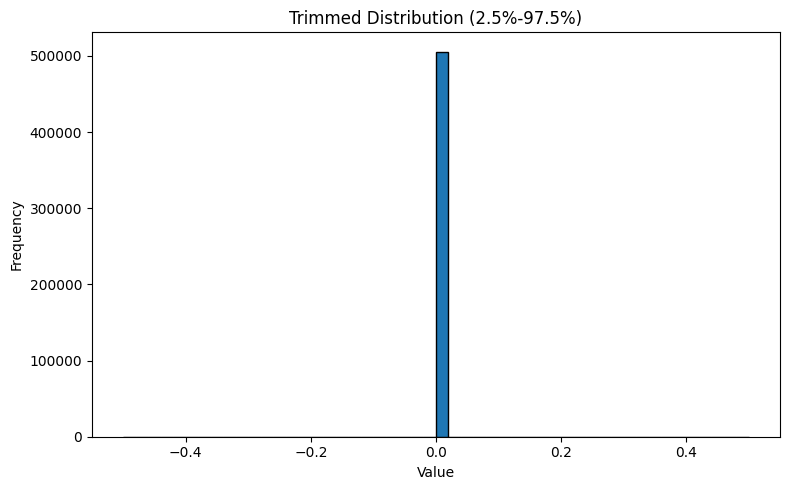

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Flatten data to 1D
# ---------------------------------------
data = all_par_SWM[:, 0, :].ravel()

# ---------------------------------------
# 2. Remove NaN, 0, -1
# ---------------------------------------
mask = (~np.isnan(data)) & (data != -1) #& (data != 0)
data = data[mask]

# ---------------------------------------
# 3. Trim both tails (2.5% each side)
# Keep central 95% of distribution
# ---------------------------------------
lower = np.percentile(data, 2.5)
upper = np.percentile(data, 97.5)

trimmed_data = data[(data >= lower) & (data <= upper)]

# ---------------------------------------
# 4. Print summary
# ---------------------------------------
print("Original n:", data.size)
print("Trimmed n :", trimmed_data.size)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)

print("Original mean:", np.mean(data))
print("Trimmed mean :", np.mean(trimmed_data))

# ---------------------------------------
# 5. Histogram
# ---------------------------------------
plt.figure(figsize=(8,5))
plt.hist(trimmed_data, bins=50, edgecolor='black')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Trimmed Distribution (2.5%-97.5%)")

plt.tight_layout()
plt.show()

## AFD - perpendicular (U-fiber)

In [8]:
all_perpav_SWM = []

for subj in subject_dirs:
    subj_path = os.path.join(base_dir, subj)
    lh_path = os.path.join(subj_path, 'L_todi_PrCG-PoCG_new', 'L_fsLR32k_afd-perp-av_results.txt')
    rh_path = os.path.join(subj_path, 'R_todi_PrCG-PoCG_new', 'R_fsLR32k_afd-perp-av_results.txt') 

    try:
        lh_perpav = np.loadtxt(lh_path)
        rh_perpav = np.loadtxt(rh_path)

        # column 0 (0mm), 2 (1mm), 4 (2mm)
        perpav_0mm = np.concatenate((lh_perpav[:, 0], rh_perpav[:, 0]), axis=0)
        perpav_1mm = np.concatenate((lh_perpav[:, 2], rh_perpav[:, 2]), axis=0)
        perpav_2mm = np.concatenate((lh_perpav[:, 4], rh_perpav[:, 4]), axis=0)
        perpav_3mm = np.concatenate((lh_perpav[:, 6], rh_perpav[:, 6]), axis=0)

        # Convert -1 to NaN for missing values
        perpav_0mm[perpav_0mm == -1] = np.nan
        perpav_1mm[perpav_1mm == -1] = np.nan
        perpav_2mm[perpav_2mm == -1] = np.nan
        perpav_3mm[perpav_3mm == -1] = np.nan

        perpav_SWM = np.vstack([perpav_0mm, perpav_1mm, perpav_2mm, perpav_3mm])  # shape: (3, vertices)
        
        all_perpav_SWM.append(perpav_SWM)
    except Exception as e:
        print(f"Error loading subject {subj}: {e}")

# shape: (n_subjects, 3, vertices)
all_perpav_SWM = np.stack(all_perpav_SWM, axis=0)
mean_perpav_SWM = np.nanmean(all_perpav_SWM, axis=0)  # shape: (3, vertices)

/tmp/ipykernel_23193/116742348.py:32: RuntimeWarning: Mean of empty slice
  mean_perpav_SWM = np.nanmean(all_perpav_SWM, axis=0)  # shape: (3, vertices)


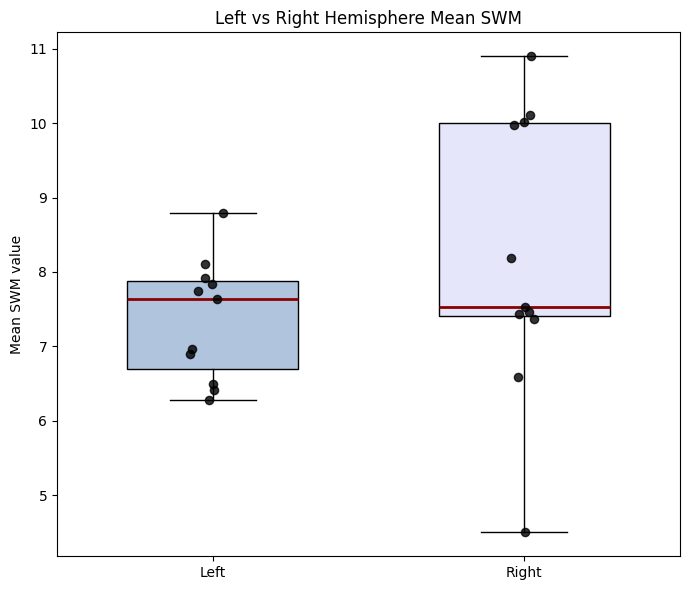

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Remove nan, 0, and -1 values
# ---------------------------------------
data = all_perpav_SWM.astype(float).copy()
invalid_mask = (np.isnan(data) | (data == 0) | (data == -1))
data[invalid_mask] = np.nan

# ---------------------------------------
# 2. Split left / right hemisphere
# Assumes vertices are ordered:
# left hemisphere first, right hemisphere second
# ---------------------------------------
n_vertices = data.shape[2]
half = n_vertices // 2

left_data  = data[:, :, :half]
right_data = data[:, :, half:]

# ---------------------------------------
# 3. Compute subject-wise mean
# ---------------------------------------
left_means  = np.nanmean(left_data, axis=(1, 2))
right_means = np.nanmean(right_data, axis=(1, 2))

# ---------------------------------------
# 4. Create box-whisker plot
# ---------------------------------------
plt.figure(figsize=(7, 6))

bp = plt.boxplot(
    [left_means, right_means],
    patch_artist=True,
    widths=0.55,
    labels=["Left", "Right"],
    boxprops=dict(edgecolor='black'),
    medianprops=dict(color='darkred', linewidth=2),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    flierprops=dict(marker='o', markersize=6, markerfacecolor='gray')
)

# Fill box colors
bp['boxes'][0].set_facecolor('lightsteelblue')
bp['boxes'][1].set_facecolor('lavender')

# Overlay individual subject values
x1 = np.random.normal(1, 0.04, size=len(left_means))
x2 = np.random.normal(2, 0.04, size=len(right_means))

plt.scatter(x1, left_means, color='black', s=35, zorder=3, alpha=0.8)
plt.scatter(x2, right_means, color='black', s=35, zorder=3, alpha=0.8)

plt.ylabel("Mean SWM value")
plt.title("Left vs Right Hemisphere Mean SWM")
plt.tight_layout()
plt.show()

Original n: 510095
Trimmed n : 505766
Lower cutoff: 0.0
Upper cutoff: 0.0
Original mean: 0.0633920295524363
Trimmed mean : 0.0


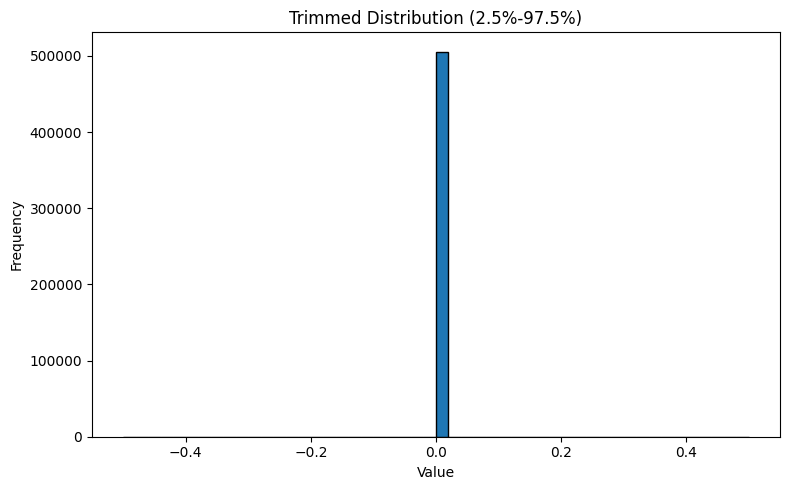

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Flatten data to 1D
# ---------------------------------------
data = all_perpav_SWM[:, 0, :].ravel()

# ---------------------------------------
# 2. Remove NaN, 0, -1
# ---------------------------------------
mask = (~np.isnan(data)) & (data != -1) #& (data != -1)
data = data[mask]

# ---------------------------------------
# 3. Trim both tails (2.5% each side)
# Keep central 95% of distribution
# ---------------------------------------
lower = np.percentile(data, 2.5)
upper = np.percentile(data, 97.5)

trimmed_data = data[(data >= lower) & (data <= upper)]

# ---------------------------------------
# 4. Print summary
# ---------------------------------------
print("Original n:", data.size)
print("Trimmed n :", trimmed_data.size)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)

print("Original mean:", np.mean(data))
print("Trimmed mean :", np.mean(trimmed_data))

# ---------------------------------------
# 5. Histogram
# ---------------------------------------
plt.figure(figsize=(8,5))
plt.hist(trimmed_data, bins=50, edgecolor='black')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Trimmed Distribution (2.5%-97.5%)")

plt.tight_layout()
plt.show()

## AFD - parallel (Long-range fiber)

In [11]:
base_dir = '/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_noregrid'
subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130', 
    'PNC037_HC116', 'PNC038_HC140'
]

In [12]:
all_par_SWM = []

for subj in subject_dirs:
    subj_path = os.path.join(base_dir, subj)
    lh_path = os.path.join(subj_path, 'L_todi_FL-IPL_new', 'L_fsLR32k_afd-par_results.txt')
    rh_path = os.path.join(subj_path, 'R_todi_FL-IPL_new', 'R_fsLR32k_afd-par_results.txt') 

    try:
        lh_par = np.loadtxt(lh_path)
        rh_par = np.loadtxt(rh_path)

        # column 0 (0mm), 2 (1mm), 4 (2mm)
        par_0mm = np.concatenate((lh_par[:, 0], rh_par[:, 0]), axis=0)
        par_1mm = np.concatenate((lh_par[:, 2], rh_par[:, 2]), axis=0)
        par_2mm = np.concatenate((lh_par[:, 4], rh_par[:, 4]), axis=0)
        par_3mm = np.concatenate((lh_par[:, 6], rh_par[:, 6]), axis=0)

        # Convert -1 to NaN for missing values
        par_0mm[par_0mm == -1] = np.nan
        par_1mm[par_1mm == -1] = np.nan
        par_2mm[par_2mm == -1] = np.nan
        par_3mm[par_3mm == -1] = np.nan

        par_SWM = np.vstack([par_0mm, par_1mm, par_2mm, par_3mm])  # shape: (3, vertices)
        
        all_par_SWM.append(par_SWM)
    except Exception as e:
        print(f"Error loading subject {subj}: {e}")

# shape: (n_subjects, 3, vertices)
all_par_SWM = np.stack(all_par_SWM, axis=0)
mean_par_SWM = np.nanmean(all_par_SWM, axis=0)  # shape: (3, vertices)

Error loading subject PNC022_HC132: /host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_noregrid/PNC022_HC132/L_todi_FL-IPL_new/L_fsLR32k_afd-par_results.txt not found.


/tmp/ipykernel_23193/2210952223.py:32: RuntimeWarning: Mean of empty slice
  mean_par_SWM = np.nanmean(all_par_SWM, axis=0)  # shape: (3, vertices)


Original n: 17206
Trimmed n : 16344
Lower cutoff: 0.0027993962500000003
Upper cutoff: 589.759
Original mean: 51.30840559189823
Trimmed mean : 23.066257296804945


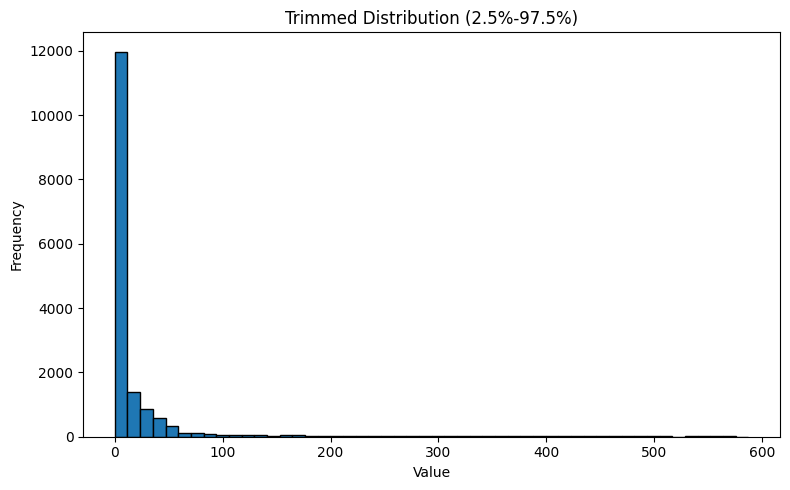

In [247]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Flatten data to 1D
# ---------------------------------------
data = all_par_SWM[:, :, :].ravel()

# ---------------------------------------
# 2. Remove NaN, 0, -1
# ---------------------------------------
mask = (~np.isnan(data)) & (data != 0) & (data != -1)
data = data[mask]

# ---------------------------------------
# 3. Trim both tails (2.5% each side)
# Keep central 95% of distribution
# ---------------------------------------
lower = np.percentile(data, 2.5)
upper = np.percentile(data, 97.5)

trimmed_data = data[(data >= lower) & (data <= upper)]

# ---------------------------------------
# 4. Print summary
# ---------------------------------------
print("Original n:", data.size)
print("Trimmed n :", trimmed_data.size)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)

print("Original mean:", np.mean(data))
print("Trimmed mean :", np.mean(trimmed_data))

# ---------------------------------------
# 5. Histogram
# ---------------------------------------
plt.figure(figsize=(8,5))
plt.hist(trimmed_data, bins=50, edgecolor='black')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Trimmed Distribution (2.5%-97.5%)")

plt.tight_layout()
plt.show()

## AFD - perpendicular (Long-range fiber)

In [264]:
all_perpav_SWM = []

for subj in subject_dirs:
    subj_path = os.path.join(base_dir, subj)
    lh_path = os.path.join(subj_path, 'L_todi_FL-IPL_new', 'L_fsLR32k_afd-perp-av_results.txt')
    rh_path = os.path.join(subj_path, 'R_todi_FL-IPL_new', 'R_fsLR32k_afd-perp-av_results.txt') 

    try:
        lh_perpav = np.loadtxt(lh_path)
        rh_perpav = np.loadtxt(rh_path)

        # column 0 (0mm), 2 (1mm), 4 (2mm)
        perpav_0mm = np.concatenate((lh_perpav[:, 0], rh_perpav[:, 0]), axis=0)
        perpav_1mm = np.concatenate((lh_perpav[:, 2], rh_perpav[:, 2]), axis=0)
        perpav_2mm = np.concatenate((lh_perpav[:, 4], rh_perpav[:, 4]), axis=0)
        perpav_3mm = np.concatenate((lh_perpav[:, 6], rh_perpav[:, 6]), axis=0)

        # Convert -1 to NaN for missing values
        perpav_0mm[perpav_0mm == -1] = np.nan
        perpav_1mm[perpav_1mm == -1] = np.nan
        perpav_2mm[perpav_2mm == -1] = np.nan
        perpav_3mm[perpav_3mm == -1] = np.nan

        perpav_SWM = np.vstack([perpav_0mm, perpav_1mm, perpav_2mm, perpav_3mm])  # shape: (3, vertices)
        
        all_perpav_SWM.append(perpav_SWM)
    except Exception as e:
        print(f"Error loading subject {subj}: {e}")

# shape: (n_subjects, 3, vertices)
all_perpav_SWM = np.stack(all_perpav_SWM, axis=0)
mean_perpav_SWM = np.nanmean(all_perpav_SWM, axis=0)  # shape: (3, vertices)

Error loading subject PNC022_HC132: /host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_noregrid/PNC022_HC132/L_todi_FL-IPL_new/L_fsLR32k_afd-perp-av_results.txt not found.


/tmp/ipykernel_405644/2801023337.py:32: RuntimeWarning: Mean of empty slice
  mean_perpav_SWM = np.nanmean(all_perpav_SWM, axis=0)  # shape: (3, vertices)


Original n: 3502
Trimmed n : 3327
Lower cutoff: 0.00450418
Upper cutoff: 30.927697499999997
Original mean: 6.615196243597944
Trimmed mean : 5.87761981428915


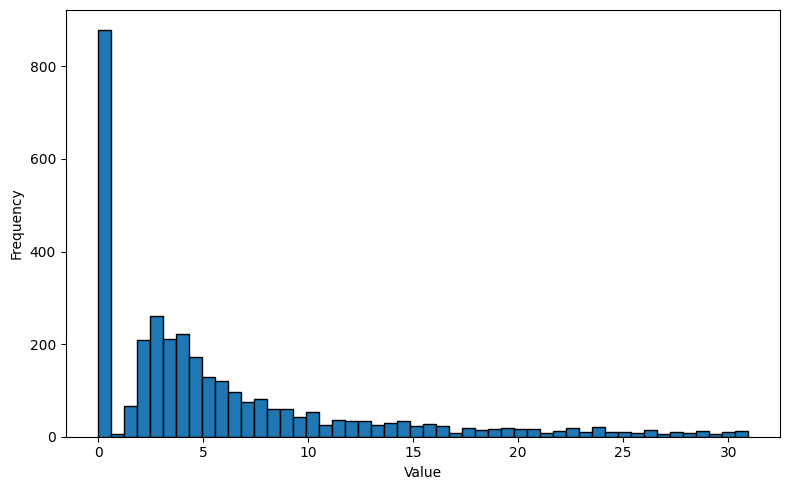

In [268]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Flatten data to 1D
# ---------------------------------------
data = all_perpav_SWM[:, 3, :].ravel()

# ---------------------------------------
# 2. Remove NaN, 0, -1
# ---------------------------------------
mask = (~np.isnan(data)) & (data != 0) & (data != -1)
data = data[mask]

# ---------------------------------------
# 3. Trim both tails (2.5% each side)
# Keep central 95% of distribution
# ---------------------------------------
lower = np.percentile(data, 2.5)
upper = np.percentile(data, 97.5)

trimmed_data = data[(data >= lower) & (data <= upper)]

# ---------------------------------------
# 4. Print summary
# ---------------------------------------
print("Original n:", data.size)
print("Trimmed n :", trimmed_data.size)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)

print("Original mean:", np.mean(data))
print("Trimmed mean :", np.mean(trimmed_data))

# ---------------------------------------
# 5. Histogram
# ---------------------------------------
plt.figure(figsize=(8,5))
plt.hist(trimmed_data, bins=50, edgecolor='black')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("")

plt.tight_layout()
plt.show()

## From here: real analysis

In [13]:
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from nibabel.streamlines import load
from scipy.spatial import cKDTree

# -------------------------
# paths
# -------------------------
tract_dir = '/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_prob'
lap_dir = '/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd'

subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130',
    'PNC037_HC116', 'PNC038_HC140'
]

### U-fiber (left)

In [14]:
# -------------------------
# store results
# -------------------------
short_L_subject_means = []   # each subject: [0-1, 1-2, 2-3]

# -------------------------
# loop subjects
# -------------------------
for sub in subject_dirs:

    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-*_hemi-L_space-dwi_PrCG-PoCG_new.tck"
    )

    track_files = glob.glob(pattern)
    if len(track_files) == 0:
        print("No tract file:", sub)
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "L_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    print("\nProcessing:", sub)

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # -------------------------
    # build Laplacian depth bins
    # -------------------------
    lap_points_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }
    lap_dirs_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }

    for sl in lap:

        depth = 0.0

        for i in range(1, len(sl)-1):

            seg = np.linalg.norm(sl[i] - sl[i-1])
            depth += seg

            p = sl[i]

            v = sl[i+1] - sl[i-1]
            nv = np.linalg.norm(v)
            if nv == 0:
                continue
            v = v / nv

            if depth < 1.0:
                lap_points_bins["0-1"].append(p)
                lap_dirs_bins["0-1"].append(v)

            elif depth < 2.0:
                lap_points_bins["1-2"].append(p)
                lap_dirs_bins["1-2"].append(v)

            elif depth < 3.0:
                lap_points_bins["2-3"].append(p)
                lap_dirs_bins["2-3"].append(v)

            else:
                break

    # convert to arrays + trees
    trees = {}
    for k in lap_points_bins:

        pts = np.array(lap_points_bins[k])
        dirs = np.array(lap_dirs_bins[k])

        if len(pts) < 10:
            trees[k] = None
        else:
            trees[k] = (cKDTree(pts), dirs)

    # -------------------------
    # compute angles per depth
    # -------------------------
    subject_result = []

    for depth_bin in ["0-1", "1-2", "2-3"]:

        if trees[depth_bin] is None:
            subject_result.append(np.nan)
            continue

        tree, lap_dirs = trees[depth_bin]

        angles = []

        for sl in tract:

            for i in range(1, len(sl)-1):

                p = sl[i]

                t = sl[i+1] - sl[i-1]
                nt = np.linalg.norm(t)
                if nt == 0:
                    continue
                t = t / nt

                dist, idx = tree.query(p, k=1)

                if dist > 1.0:
                    continue

                l = lap_dirs[idx]

                cosang = np.abs(np.dot(t, l))
                cosang = np.clip(cosang, -1, 1)

                theta = np.degrees(np.arccos(cosang))
                angles.append(theta)

        angles = np.array(angles)

        if len(angles) == 0:
            subject_result.append(np.nan)
        else:
            subject_result.append(np.mean(angles))

    short_L_subject_means.append(subject_result)

    print(f"  mean angle (0–1 mm) = {subject_result[0]:.2f}")
    print(f"  mean angle (1–2 mm) = {subject_result[1]:.2f}")
    print(f"  mean angle (2–3 mm) = {subject_result[2]:.2f}")

# -------------------------
# group statistics
# -------------------------
short_L_subject_means = np.array(short_L_subject_means)

print("\n===== GROUP RESULT =====")

for i, label in enumerate(["0–1 mm", "1–2 mm", "2–3 mm"]):
    vals = short_L_subject_means[:, i]
    print(f"{label}: {np.nanmean(vals):.2f} ± {np.nanstd(vals):.2f}")

# -------------------------
# plot
# -------------------------
plt.figure()

x = np.arange(len(subject_dirs))
for i, label in enumerate(["0–1", "1–2", "2–3"]):
    plt.plot(x, short_L_subject_means[:, i], marker='o', label=label)

plt.xticks(x, subject_dirs, rotation=45)
plt.ylabel("Mean angle (deg)")
plt.title("Depth-dependent SWM Orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()


Processing: PNC003_HC082
  mean angle (0–1 mm) = 53.98
  mean angle (1–2 mm) = 47.17
  mean angle (2–3 mm) = 42.16

Processing: PNC006_HC081
  mean angle (0–1 mm) = 58.09
  mean angle (1–2 mm) = 51.67
  mean angle (2–3 mm) = 45.60

Processing: PNC011_HC083
  mean angle (0–1 mm) = 56.79
  mean angle (1–2 mm) = 50.09
  mean angle (2–3 mm) = 44.85

Processing: PNC018_HC076
  mean angle (0–1 mm) = 54.91
  mean angle (1–2 mm) = 48.63
  mean angle (2–3 mm) = 43.34

Processing: PNC019_HC062
  mean angle (0–1 mm) = 53.46
  mean angle (1–2 mm) = 47.85
  mean angle (2–3 mm) = 42.53

Processing: PNC022_HC132
  mean angle (0–1 mm) = 56.79
  mean angle (1–2 mm) = 49.91
  mean angle (2–3 mm) = 42.36

Processing: PNC024_HC088
  mean angle (0–1 mm) = 58.33
  mean angle (1–2 mm) = 52.19
  mean angle (2–3 mm) = 46.63

Processing: PNC025_HC128
  mean angle (0–1 mm) = 57.31
  mean angle (1–2 mm) = 50.33
  mean angle (2–3 mm) = 43.44

Processing: PNC026_HC130
  mean angle (0–1 mm) = 55.99
  mean angle (1–

KeyboardInterrupt: 

/tmp/ipykernel_32409/762109975.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


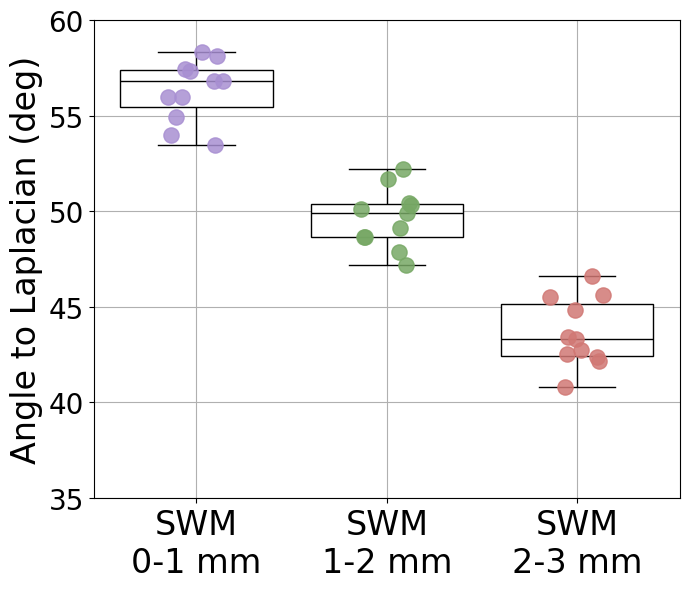

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# Step 1: Long-form dataframe
# -------------------------
df_1 = pd.DataFrame({
    'Angle': short_L_subject_means[:, 0],
    'Depth': 'SWM\n0-1 mm'
})

df_2 = pd.DataFrame({
    'Angle': short_L_subject_means[:, 1],
    'Depth': 'SWM\n1-2 mm'
})
 
df_3 = pd.DataFrame({
    'Angle': short_L_subject_means[:, 2],
    'Depth': 'SWM\n2-3 mm'
})

df_all = pd.concat([df_1, df_2, df_3], ignore_index=True)

# -------------------------
# Step 2: Plot
# -------------------------
plt.figure(figsize=(7,6))

depth_labels = ['SWM\n0-1 mm', 'SWM\n1-2 mm', 'SWM\n2-3 mm']

sns.boxplot(
    x='Depth',
    y='Angle',
    data=df_all,
    order=depth_labels,
    linewidth=1,
    showfliers=False,
    showmeans=False,
    width=0.8,
    palette={
        'SWM\n0-1 mm': 'white',
        'SWM\n1-2 mm': 'white',
        'SWM\n2-3 mm': 'white'
    },
    #medianprops={'visible': True},
    boxprops=dict(edgecolor='black'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='black', linewidth=1)
)

# -------------------------
# Step 3: Dots
# -------------------------
dot_colors = {
    'SWM\n0-1 mm': '#A88FD2',
    'SWM\n1-2 mm': '#77A865',
    'SWM\n2-3 mm': '#D17874'
}

for i, depth in enumerate(depth_labels):

    vals = df_all[df_all['Depth'] == depth]['Angle'].values
    vals = vals[~np.isnan(vals)]

    x_jitter = i + np.random.uniform(-0.15, 0.15, len(vals))

    plt.scatter(
        x_jitter,
        vals,
        color=dot_colors[depth],
        s=120,
        alpha=0.85,
        zorder=10
    )

# -------------------------
# Step 4: Style
# -------------------------
plt.xticks(
    ticks=range(len(depth_labels)),
    labels=depth_labels,
    fontsize=24
)

plt.axhline(0, color='black', linestyle='-', linewidth=1)

plt.xlabel('', fontsize=24)
plt.ylabel('Angle to Laplacian (deg)', fontsize=24)

plt.yticks(fontsize=20)
plt.grid(True)

plt.ylim(35, 60)

plt.tight_layout()
plt.show()

Processing: PNC003_HC082

0-1 Whole = 53.98   Gyri = 49.78   Sulci = 56.41
1-2 Whole = 47.17   Gyri = 40.91   Sulci = 50.96
2-3 Whole = 42.16   Gyri = 37.18   Sulci = 46.82
Processing: PNC006_HC081

0-1 Whole = 58.09   Gyri = 48.65   Sulci = 62.19
1-2 Whole = 51.67   Gyri = 41.68   Sulci = 56.68
2-3 Whole = 45.60   Gyri = 37.79   Sulci = 52.02
Processing: PNC011_HC083

0-1 Whole = 56.79   Gyri = 49.65   Sulci = 59.60
1-2 Whole = 50.09   Gyri = 40.49   Sulci = 54.17
2-3 Whole = 44.85   Gyri = 36.16   Sulci = 50.26
Processing: PNC018_HC076

0-1 Whole = 54.91   Gyri = 48.15   Sulci = 58.22
1-2 Whole = 48.63   Gyri = 41.13   Sulci = 52.67
2-3 Whole = 43.34   Gyri = 37.37   Sulci = 47.89
Processing: PNC019_HC062

0-1 Whole = 53.46   Gyri = 48.79   Sulci = 56.86
1-2 Whole = 47.85   Gyri = 40.00   Sulci = 53.06
2-3 Whole = 42.53   Gyri = 35.63   Sulci = 49.22
Processing: PNC022_HC132

0-1 Whole = 56.79   Gyri = 51.00   Sulci = 59.46
1-2 Whole = 49.91   Gyri = 42.09   Sulci = 53.88
2-3 Whole =

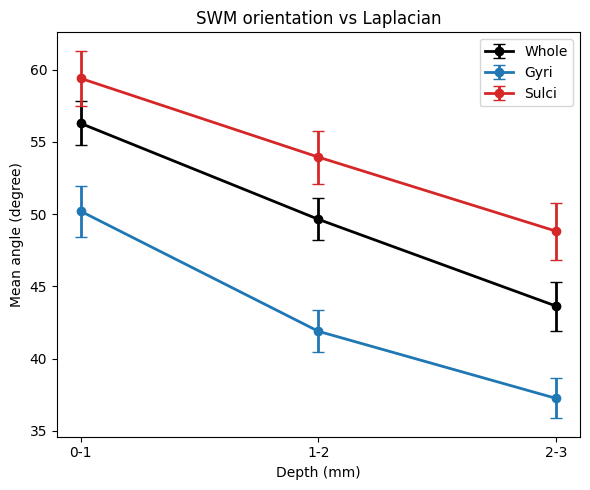

In [18]:
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import nibabel as nb

from nibabel.streamlines import load
from scipy.spatial import cKDTree

# ---------------------------------------------------
# paths
# ---------------------------------------------------
tract_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_prob"
lap_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd"

subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130',
    'PNC037_HC116', 'PNC038_HC140'
]

ses_dirs = ['03', '03', '03', '03', '03', '03', 'a1', 'a1', 'a1', 'a1', 'a1']

depth_bins = ["0-1", "1-2", "2-3"]
regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# store subject results
# ---------------------------------------------------
SF_left_group_results = {
    d: {r: [] for r in regions}
    for d in depth_bins
}

# ---------------------------------------------------
# subject loop
# ---------------------------------------------------
for sub, ses in zip(subject_dirs, ses_dirs):

    print("="*60)
    print("Processing:", sub)

    sub_id = sub.split("_")[0].replace("PNC", "")

    # ---------------------------------------------------
    # tract
    # ---------------------------------------------------
    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-L_space-dwi_PrCG-PoCG_new.tck"
    )

    track_files = glob.glob(pattern)

    if len(track_files) == 0:
        print("No tract")
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "L_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # ---------------------------------------------------
    # curvature
    # ---------------------------------------------------
    cfile = glob.glob(
        f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
        f"sub-{sub.split('_')[0]}/ses-{ses}/maps/"
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-L_surf-fsLR-32k_label-curv.func.gii"
    )[0]

    cdata = nb.load(cfile).darrays[0].data

    # ---------------------------------------------------
    # Laplacian database
    # ---------------------------------------------------
    lap_points = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    lap_dirs = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    for vidx, sl in enumerate(lap):

        if vidx >= len(cdata):
            break

        is_gyrus = cdata[vidx] < 0
        is_sulcus = cdata[vidx] > 0

        depth = 0

        for i in range(1, len(sl)-1):

            depth += np.linalg.norm(sl[i]-sl[i-1])

            if depth >= 3:
                break

            p = sl[i]

            v = sl[i+1]-sl[i-1]
            nv = np.linalg.norm(v)

            if nv == 0:
                continue

            v /= nv

            if depth < 1:
                dbin = "0-1"
            elif depth < 2:
                dbin = "1-2"
            else:
                dbin = "2-3"

            lap_points[dbin]["whole"].append(p)
            lap_dirs[dbin]["whole"].append(v)

            if is_gyrus:
                lap_points[dbin]["gyrus"].append(p)
                lap_dirs[dbin]["gyrus"].append(v)

            elif is_sulcus:
                lap_points[dbin]["sulcus"].append(p)
                lap_dirs[dbin]["sulcus"].append(v)

    # ---------------------------------------------------
    # KDTree
    # ---------------------------------------------------
    trees = {}

    for d in depth_bins:

        trees[d] = {}

        for r in regions:

            pts = np.array(lap_points[d][r])
            dirs = np.array(lap_dirs[d][r])

            if len(pts) < 10:
                trees[d][r] = None
            else:
                trees[d][r] = (cKDTree(pts), dirs)

    # ---------------------------------------------------
    # angle computation
    # ---------------------------------------------------
    subject_result = {
        d: {}
        for d in depth_bins
    }

    for d in depth_bins:

        for r in regions:

            if trees[d][r] is None:
                subject_result[d][r] = np.nan
                continue

            tree, lapdir = trees[d][r]

            angles = []

            for sl in tract:

                for i in range(1, len(sl)-1):

                    p = sl[i]

                    t = sl[i+1]-sl[i-1]

                    nt = np.linalg.norm(t)

                    if nt == 0:
                        continue

                    t /= nt

                    dist, idx = tree.query(p)

                    if dist > 1:
                        continue

                    l = lapdir[idx]

                    cosang = np.abs(np.dot(t, l))
                    cosang = np.clip(cosang, -1, 1)

                    theta = np.degrees(np.arccos(cosang))

                    angles.append(theta)

            if len(angles) == 0:
                subject_result[d][r] = np.nan
            else:
                subject_result[d][r] = np.mean(angles)

            SF_left_group_results[d][r].append(subject_result[d][r])

    print()

    for d in depth_bins:
        print(
            d,
            "Whole = %.2f   Gyri = %.2f   Sulci = %.2f"
            % (
                subject_result[d]["whole"],
                subject_result[d]["gyrus"],
                subject_result[d]["sulcus"],
            )
        )

# ---------------------------------------------------
# group statistics
# ---------------------------------------------------
print("\n")
print("="*60)
print("GROUP RESULT")
print("="*60)

group_mean = {}
group_std = {}

for r in regions:

    group_mean[r] = []
    group_std[r] = []

    print("\n", r)

    for d in depth_bins:

        vals = np.array(SF_left_group_results[d][r])

        mean = np.nanmean(vals)
        std = np.nanstd(vals)

        group_mean[r].append(mean)
        group_std[r].append(std)

        print(f"{d} mm : {mean:.2f} ± {std:.2f}")

# ---------------------------------------------------
# plot
# ---------------------------------------------------
plt.figure(figsize=(6,5))

colors = {
    "whole":"black",
    "gyrus":"tab:blue",
    "sulcus":"tab:red"
}

labels = {
    "whole":"Whole",
    "gyrus":"Gyri",
    "sulcus":"Sulci"
}

x = np.arange(3)

for r in regions:

    plt.errorbar(
        x,
        group_mean[r],
        yerr=group_std[r],
        marker='o',
        linewidth=2,
        capsize=4,
        label=labels[r],
        color=colors[r]
    )

plt.xticks(x, ["0-1","1-2","2-3"])
plt.xlabel("Depth (mm)")
plt.ylabel("Mean angle (degree)")
plt.title("SWM orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

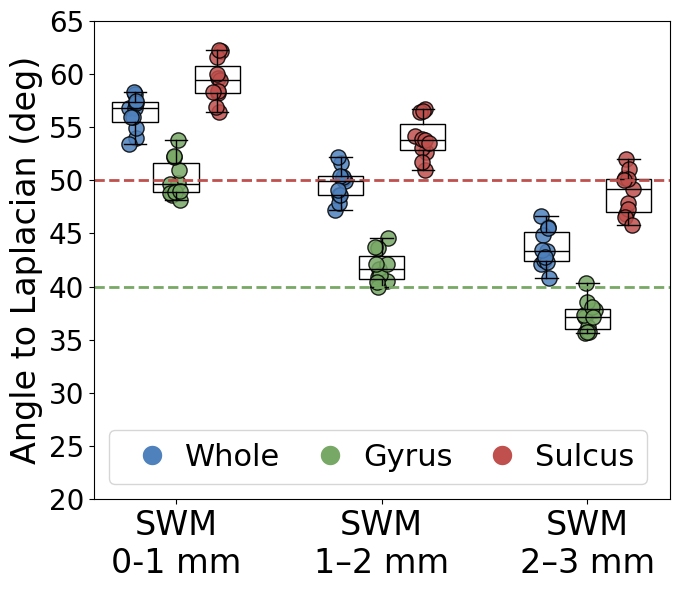

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "whole": "#4F81BD",
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 0,
    "1-2": 2.5,
    "2-3": 5
}

offsets = {
    "whole": -0.5,
    "gyrus": 0.0,
    "sulcus": 0.5
}

width = 0.55

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(SF_left_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([0, 2.5, 5])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(50, color="#C0504D", linestyle="--", linewidth=2)
ax.axhline(40, color="#77A865", linestyle="--", linewidth=1)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#4F81BD', markersize=15,
               label='Whole'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22)
ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

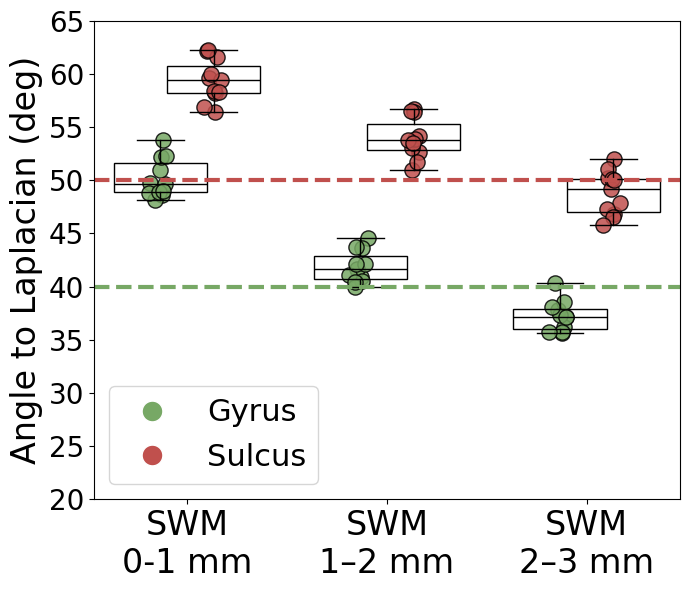

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 1,
    "1-2": 2.5,
    "2-3": 4
}

offsets = {
    "gyrus": -0.2,
    "sulcus": 0.2
}

width = 0.7

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(SF_left_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([1, 2.5, 4])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(50, color="#C0504D", linestyle="--", linewidth=3)
ax.axhline(40, color="#77A865", linestyle="--", linewidth=3)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22)
#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

### U-fiber (right)


Processing: PNC003_HC082
  mean angle (0–1 mm) = 53.12
  mean angle (1–2 mm) = 46.48
  mean angle (2–3 mm) = 40.94

Processing: PNC006_HC081
  mean angle (0–1 mm) = 57.27
  mean angle (1–2 mm) = 48.69
  mean angle (2–3 mm) = 42.23

Processing: PNC011_HC083
  mean angle (0–1 mm) = 54.68
  mean angle (1–2 mm) = 48.50
  mean angle (2–3 mm) = 42.77

Processing: PNC018_HC076
  mean angle (0–1 mm) = 54.64
  mean angle (1–2 mm) = 47.20
  mean angle (2–3 mm) = 41.97

Processing: PNC019_HC062
  mean angle (0–1 mm) = 57.51
  mean angle (1–2 mm) = 49.81
  mean angle (2–3 mm) = 41.46

Processing: PNC022_HC132
  mean angle (0–1 mm) = 53.67
  mean angle (1–2 mm) = 45.41
  mean angle (2–3 mm) = 38.67

Processing: PNC024_HC088
  mean angle (0–1 mm) = 58.15
  mean angle (1–2 mm) = 51.80
  mean angle (2–3 mm) = 45.59

Processing: PNC025_HC128
  mean angle (0–1 mm) = 58.78
  mean angle (1–2 mm) = 51.32
  mean angle (2–3 mm) = 45.49

Processing: PNC026_HC130
  mean angle (0–1 mm) = 56.63
  mean angle (1–

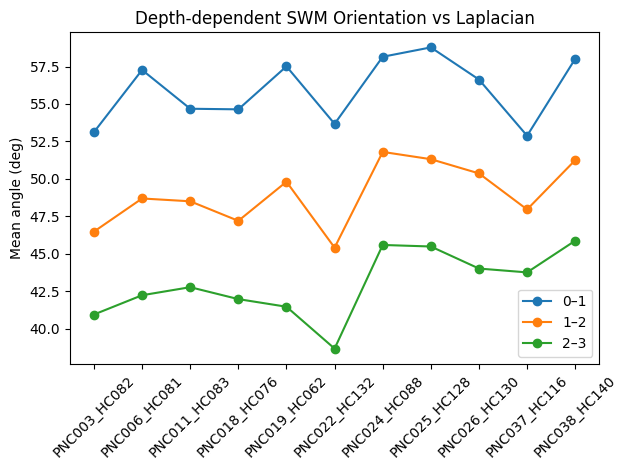

In [81]:
# -------------------------
# store results
# -------------------------
short_R_subject_means = []   # each subject: [0-1, 1-2, 2-3]

# -------------------------
# loop subjects
# -------------------------
for sub in subject_dirs:

    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-*_hemi-R_space-dwi_PrCG-PoCG_new.tck"
    )

    track_files = glob.glob(pattern)
    if len(track_files) == 0:
        print("No tract file:", sub)
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "R_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    print("\nProcessing:", sub)

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # -------------------------
    # build Laplacian depth bins
    # -------------------------
    lap_points_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }
    lap_dirs_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }

    for sl in lap:

        depth = 0.0

        for i in range(1, len(sl)-1):

            seg = np.linalg.norm(sl[i] - sl[i-1])
            depth += seg

            p = sl[i]

            v = sl[i+1] - sl[i-1]
            nv = np.linalg.norm(v)
            if nv == 0:
                continue
            v = v / nv

            if depth < 1.0:
                lap_points_bins["0-1"].append(p)
                lap_dirs_bins["0-1"].append(v)

            elif depth < 2.0:
                lap_points_bins["1-2"].append(p)
                lap_dirs_bins["1-2"].append(v)

            elif depth < 3.0:
                lap_points_bins["2-3"].append(p)
                lap_dirs_bins["2-3"].append(v)

            else:
                break

    # convert to arrays + trees
    trees = {}
    for k in lap_points_bins:

        pts = np.array(lap_points_bins[k])
        dirs = np.array(lap_dirs_bins[k])

        if len(pts) < 10:
            trees[k] = None
        else:
            trees[k] = (cKDTree(pts), dirs)

    # -------------------------
    # compute angles per depth
    # -------------------------
    subject_result = []

    for depth_bin in ["0-1", "1-2", "2-3"]:

        if trees[depth_bin] is None:
            subject_result.append(np.nan)
            continue

        tree, lap_dirs = trees[depth_bin]

        angles = []

        for sl in tract:

            for i in range(1, len(sl)-1):

                p = sl[i]

                t = sl[i+1] - sl[i-1]
                nt = np.linalg.norm(t)
                if nt == 0:
                    continue
                t = t / nt

                dist, idx = tree.query(p, k=1)

                if dist > 1.0:
                    continue

                l = lap_dirs[idx]

                cosang = np.abs(np.dot(t, l))
                cosang = np.clip(cosang, -1, 1)

                theta = np.degrees(np.arccos(cosang))
                angles.append(theta)

        angles = np.array(angles)

        if len(angles) == 0:
            subject_result.append(np.nan)
        else:
            subject_result.append(np.mean(angles))

    short_R_subject_means.append(subject_result)

    print(f"  mean angle (0–1 mm) = {subject_result[0]:.2f}")
    print(f"  mean angle (1–2 mm) = {subject_result[1]:.2f}")
    print(f"  mean angle (2–3 mm) = {subject_result[2]:.2f}")

# -------------------------
# group statistics
# -------------------------
short_R_subject_means = np.array(short_R_subject_means)

print("\n===== GROUP RESULT =====")

for i, label in enumerate(["0–1 mm", "1–2 mm", "2–3 mm"]):
    vals = short_R_subject_means[:, i]
    print(f"{label}: {np.nanmean(vals):.2f} ± {np.nanstd(vals):.2f}")

# -------------------------
# plot
# -------------------------
plt.figure()

x = np.arange(len(subject_dirs))
for i, label in enumerate(["0–1", "1–2", "2–3"]):
    plt.plot(x, short_R_subject_means[:, i], marker='o', label=label)

plt.xticks(x, subject_dirs, rotation=45)
plt.ylabel("Mean angle (deg)")
plt.title("Depth-dependent SWM Orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# Step 1: Long-form dataframe
# -------------------------
df_1 = pd.DataFrame({
    'Angle': short_R_subject_means[:, 0],
    'Depth': 'SWM\n0-1 mm'
})

df_2 = pd.DataFrame({
    'Angle': short_R_subject_means[:, 1],
    'Depth': 'SWM\n1-2 mm'
})

df_3 = pd.DataFrame({
    'Angle': short_R_subject_means[:, 2],
    'Depth': 'SWM\n2-3 mm'
})

df_all = pd.concat([df_1, df_2, df_3], ignore_index=True)

# -------------------------
# Step 2: Plot
# -------------------------
plt.figure(figsize=(7,6))

depth_labels = ['SWM\n0-1 mm', 'SWM\n1-2 mm', 'SWM\n2-3 mm']

sns.boxplot(
    x='Depth',
    y='Angle',
    data=df_all,
    order=depth_labels,
    linewidth=1,
    showfliers=False,
    showmeans=False,
    width=0.8,
    palette={
        'SWM\n0-1 mm': 'white',
        'SWM\n1-2 mm': 'white',
        'SWM\n2-3 mm': 'white'
    },
    #medianprops={'visible': True},
    boxprops=dict(edgecolor='black'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='black', linewidth=1)
)

# -------------------------
# Step 3: Dots
# -------------------------
dot_colors = {
    'SWM\n0-1 mm': '#A88FD2',
    'SWM\n1-2 mm': '#77A865',
    'SWM\n2-3 mm': '#D17874'
}

for i, depth in enumerate(depth_labels):

    vals = df_all[df_all['Depth'] == depth]['Angle'].values
    vals = vals[~np.isnan(vals)]

    x_jitter = i + np.random.uniform(-0.15, 0.15, len(vals))

    plt.scatter(
        x_jitter,
        vals,
        color=dot_colors[depth],
        s=120,
        alpha=0.85,
        zorder=10
    )

# -------------------------
# Step 4: Style
# -------------------------
plt.xticks(
    ticks=range(len(depth_labels)),
    labels=depth_labels,
    fontsize=24
)

plt.axhline(0, color='black', linestyle='-', linewidth=1)

plt.xlabel('', fontsize=24)
plt.ylabel('Angle to Laplacian (deg)', fontsize=24)

plt.yticks(fontsize=20)
plt.grid(True)

plt.ylim(35, 60)

plt.tight_layout()
plt.show()

NameError: name 'short_R_subject_means' is not defined

Processing: PNC003_HC082

0-1 Whole = 53.12   Gyri = 49.96   Sulci = 55.19
1-2 Whole = 46.48   Gyri = 40.16   Sulci = 50.91
2-3 Whole = 40.94   Gyri = 33.98   Sulci = 47.65
Processing: PNC006_HC081

0-1 Whole = 57.27   Gyri = 52.49   Sulci = 59.28
1-2 Whole = 48.69   Gyri = 43.08   Sulci = 51.40
2-3 Whole = 42.23   Gyri = 36.70   Sulci = 46.81
Processing: PNC011_HC083

0-1 Whole = 54.68   Gyri = 48.52   Sulci = 58.24
1-2 Whole = 48.50   Gyri = 39.58   Sulci = 53.63
2-3 Whole = 42.77   Gyri = 34.23   Sulci = 49.41
Processing: PNC018_HC076

0-1 Whole = 54.64   Gyri = 47.54   Sulci = 58.35
1-2 Whole = 47.20   Gyri = 37.67   Sulci = 52.15
2-3 Whole = 41.97   Gyri = 32.54   Sulci = 48.48
Processing: PNC019_HC062

0-1 Whole = 57.51   Gyri = 51.28   Sulci = 60.06
1-2 Whole = 49.81   Gyri = 41.93   Sulci = 53.72
2-3 Whole = 41.46   Gyri = 35.20   Sulci = 46.51
Processing: PNC022_HC132

0-1 Whole = 53.67   Gyri = 50.45   Sulci = 55.41
1-2 Whole = 45.41   Gyri = 39.37   Sulci = 48.40
2-3 Whole =

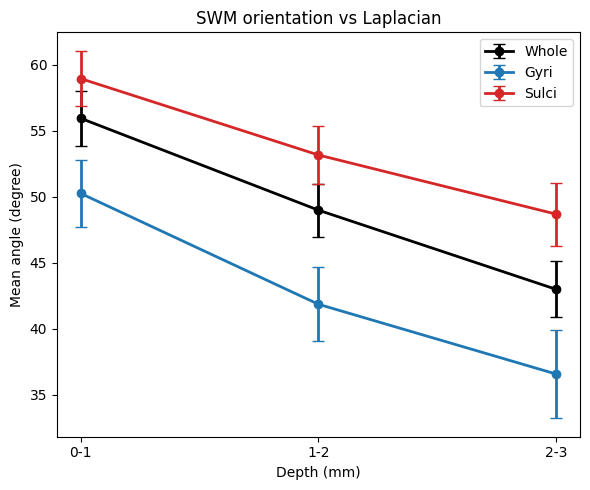

In [28]:
# ---------------------------------------------------
# paths
# ---------------------------------------------------
tract_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_prob"
lap_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd"

subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130',
    'PNC037_HC116', 'PNC038_HC140'
]

ses_dirs = ['03', '03', '03', '03', '03', '03', 'a1', 'a1', 'a1', 'a1', 'a1']

depth_bins = ["0-1", "1-2", "2-3"]
regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# store subject results
# ---------------------------------------------------
SF_right_group_results = {
    d: {r: [] for r in regions}
    for d in depth_bins
}

# ---------------------------------------------------
# subject loop
# ---------------------------------------------------
for sub, ses in zip(subject_dirs, ses_dirs):

    print("="*60)
    print("Processing:", sub)

    sub_id = sub.split("_")[0].replace("PNC", "")

    # ---------------------------------------------------
    # tract
    # ---------------------------------------------------
    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-R_space-dwi_PrCG-PoCG_new.tck"
    )

    track_files = glob.glob(pattern)

    if len(track_files) == 0:
        print("No tract")
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "R_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # ---------------------------------------------------
    # curvature
    # ---------------------------------------------------
    cfile = glob.glob(
        f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
        f"sub-{sub.split('_')[0]}/ses-{ses}/maps/"
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-R_surf-fsLR-32k_label-curv.func.gii"
    )[0]

    cdata = nb.load(cfile).darrays[0].data

    # ---------------------------------------------------
    # Laplacian database
    # ---------------------------------------------------
    lap_points = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    lap_dirs = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    for vidx, sl in enumerate(lap):

        if vidx >= len(cdata):
            break

        is_gyrus = cdata[vidx] < 0
        is_sulcus = cdata[vidx] > 0

        depth = 0

        for i in range(1, len(sl)-1):

            depth += np.linalg.norm(sl[i]-sl[i-1])

            if depth >= 3:
                break

            p = sl[i]

            v = sl[i+1]-sl[i-1]
            nv = np.linalg.norm(v)

            if nv == 0:
                continue

            v /= nv

            if depth < 1:
                dbin = "0-1"
            elif depth < 2:
                dbin = "1-2"
            else:
                dbin = "2-3"

            lap_points[dbin]["whole"].append(p)
            lap_dirs[dbin]["whole"].append(v)

            if is_gyrus:
                lap_points[dbin]["gyrus"].append(p)
                lap_dirs[dbin]["gyrus"].append(v)

            elif is_sulcus:
                lap_points[dbin]["sulcus"].append(p)
                lap_dirs[dbin]["sulcus"].append(v)

    # ---------------------------------------------------
    # KDTree
    # ---------------------------------------------------
    trees = {}

    for d in depth_bins:

        trees[d] = {}

        for r in regions:

            pts = np.array(lap_points[d][r])
            dirs = np.array(lap_dirs[d][r])

            if len(pts) < 10:
                trees[d][r] = None
            else:
                trees[d][r] = (cKDTree(pts), dirs)

    # ---------------------------------------------------
    # angle computation
    # ---------------------------------------------------
    subject_result = {
        d: {}
        for d in depth_bins
    }

    for d in depth_bins:

        for r in regions:

            if trees[d][r] is None:
                subject_result[d][r] = np.nan
                continue

            tree, lapdir = trees[d][r]

            angles = []

            for sl in tract:

                for i in range(1, len(sl)-1):

                    p = sl[i]

                    t = sl[i+1]-sl[i-1]

                    nt = np.linalg.norm(t)

                    if nt == 0:
                        continue

                    t /= nt

                    dist, idx = tree.query(p)

                    if dist > 1:
                        continue

                    l = lapdir[idx]

                    cosang = np.abs(np.dot(t, l))
                    cosang = np.clip(cosang, -1, 1)

                    theta = np.degrees(np.arccos(cosang))

                    angles.append(theta)

            if len(angles) == 0:
                subject_result[d][r] = np.nan
            else:
                subject_result[d][r] = np.mean(angles)

            SF_right_group_results[d][r].append(subject_result[d][r])

    print()

    for d in depth_bins:
        print(
            d,
            "Whole = %.2f   Gyri = %.2f   Sulci = %.2f"
            % (
                subject_result[d]["whole"],
                subject_result[d]["gyrus"],
                subject_result[d]["sulcus"],
            )
        )

# ---------------------------------------------------
# group statistics
# ---------------------------------------------------
print("\n")
print("="*60)
print("GROUP RESULT")
print("="*60)

group_mean = {}
group_std = {}

for r in regions:

    group_mean[r] = []
    group_std[r] = []

    print("\n", r)

    for d in depth_bins:

        vals = np.array(SF_right_group_results[d][r])

        mean = np.nanmean(vals)
        std = np.nanstd(vals)

        group_mean[r].append(mean)
        group_std[r].append(std)

        print(f"{d} mm : {mean:.2f} ± {std:.2f}")

# ---------------------------------------------------
# plot
# ---------------------------------------------------
plt.figure(figsize=(6,5))

colors = {
    "whole":"black",
    "gyrus":"tab:blue",
    "sulcus":"tab:red"
}

labels = {
    "whole":"Whole",
    "gyrus":"Gyri",
    "sulcus":"Sulci"
}

x = np.arange(3)

for r in regions:

    plt.errorbar(
        x,
        group_mean[r],
        yerr=group_std[r],
        marker='o',
        linewidth=2,
        capsize=4,
        label=labels[r],
        color=colors[r]
    )

plt.xticks(x, ["0-1","1-2","2-3"])
plt.xlabel("Depth (mm)")
plt.ylabel("Mean angle (degree)")
plt.title("SWM orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

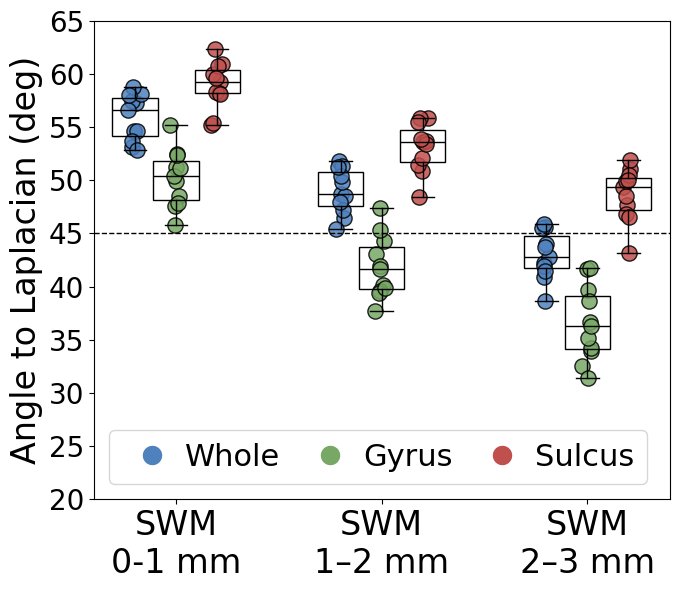

In [82]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "whole": "#4F81BD",
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 0,
    "1-2": 2.5,
    "2-3": 5
}

offsets = {
    "whole": -0.5,
    "gyrus": 0.0,
    "sulcus": 0.5
}

width = 0.55

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(SF_right_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([0, 2.5, 5])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(45, color="black", linestyle="--", linewidth=1)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#4F81BD', markersize=15,
               label='Whole'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22)
ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

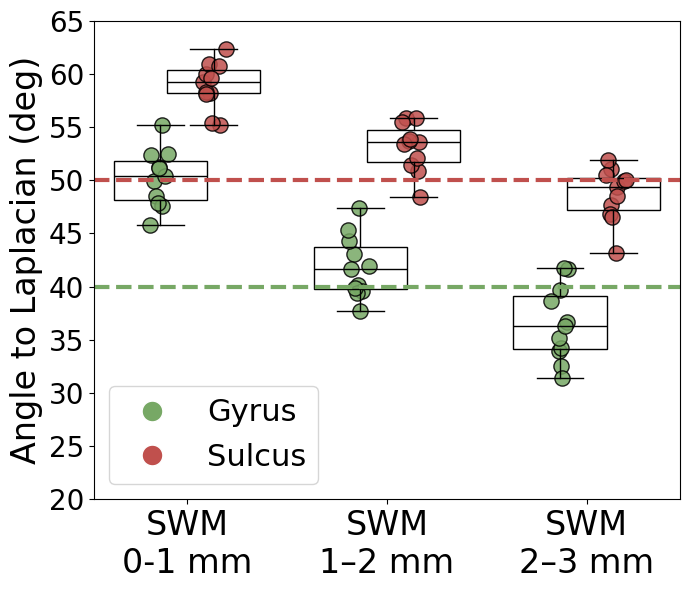

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 1,
    "1-2": 2.5,
    "2-3": 4
}

offsets = {
    "gyrus": -0.2,
    "sulcus": 0.2
}

width = 0.7

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(SF_right_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([1, 2.5, 4])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(50, color="#C0504D", linestyle="--", linewidth=3)
ax.axhline(40, color="#77A865", linestyle="--", linewidth=3)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22)
#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

### Long-range fiber (left)


Processing: PNC003_HC082
  mean angle (0–1 mm) = 41.41
  mean angle (1–2 mm) = 37.76
  mean angle (2–3 mm) = 43.24

Processing: PNC006_HC081
  mean angle (0–1 mm) = 42.58
  mean angle (1–2 mm) = 41.79
  mean angle (2–3 mm) = 48.49

Processing: PNC011_HC083
  mean angle (0–1 mm) = 45.89
  mean angle (1–2 mm) = 42.10
  mean angle (2–3 mm) = 45.30

Processing: PNC018_HC076
  mean angle (0–1 mm) = 46.42
  mean angle (1–2 mm) = 45.99
  mean angle (2–3 mm) = 51.16

Processing: PNC019_HC062
  mean angle (0–1 mm) = 39.59
  mean angle (1–2 mm) = 38.19
  mean angle (2–3 mm) = 45.21

Processing: PNC022_HC132
  mean angle (0–1 mm) = 44.87
  mean angle (1–2 mm) = 43.14
  mean angle (2–3 mm) = 46.32

Processing: PNC024_HC088
  mean angle (0–1 mm) = 41.17
  mean angle (1–2 mm) = 39.27
  mean angle (2–3 mm) = 45.43

Processing: PNC025_HC128
  mean angle (0–1 mm) = 43.46
  mean angle (1–2 mm) = 42.38
  mean angle (2–3 mm) = 45.98

Processing: PNC026_HC130
  mean angle (0–1 mm) = 48.59
  mean angle (1–

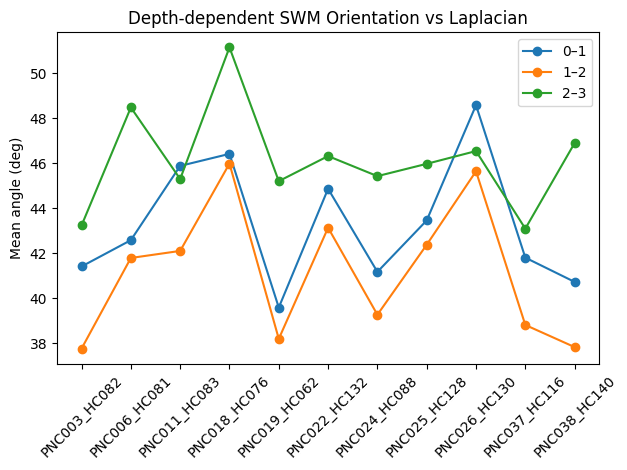

In [83]:
# -------------------------
# store results
# -------------------------
Long_L_subject_means = []   # each subject: [0-1, 1-2, 2-3]

# -------------------------
# loop subjects
# -------------------------
for sub in subject_dirs:

    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-*_hemi-L_space-dwi_FL-IPL_new2.tck"
    )

    track_files = glob.glob(pattern)
    if len(track_files) == 0:
        print("No tract file:", sub)
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "L_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    print("\nProcessing:", sub)

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # -------------------------
    # build Laplacian depth bins
    # -------------------------
    lap_points_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }
    lap_dirs_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }

    for sl in lap:

        depth = 0.0

        for i in range(1, len(sl)-1):

            seg = np.linalg.norm(sl[i] - sl[i-1])
            depth += seg

            p = sl[i]

            v = sl[i+1] - sl[i-1]
            nv = np.linalg.norm(v)
            if nv == 0:
                continue
            v = v / nv

            if depth < 1.0:
                lap_points_bins["0-1"].append(p)
                lap_dirs_bins["0-1"].append(v)

            elif depth < 2.0:
                lap_points_bins["1-2"].append(p)
                lap_dirs_bins["1-2"].append(v)

            elif depth < 3.0:
                lap_points_bins["2-3"].append(p)
                lap_dirs_bins["2-3"].append(v)

            else:
                break

    # convert to arrays + trees
    trees = {}
    for k in lap_points_bins:

        pts = np.array(lap_points_bins[k])
        dirs = np.array(lap_dirs_bins[k])

        if len(pts) < 10:
            trees[k] = None
        else:
            trees[k] = (cKDTree(pts), dirs)

    # -------------------------
    # compute angles per depth
    # -------------------------
    subject_result = []

    for depth_bin in ["0-1", "1-2", "2-3"]:

        if trees[depth_bin] is None:
            subject_result.append(np.nan)
            continue

        tree, lap_dirs = trees[depth_bin]

        angles = []

        for sl in tract:

            for i in range(1, len(sl)-1):

                p = sl[i]

                t = sl[i+1] - sl[i-1]
                nt = np.linalg.norm(t)
                if nt == 0:
                    continue
                t = t / nt

                dist, idx = tree.query(p, k=1)

                if dist > 1.0:
                    continue

                l = lap_dirs[idx]

                cosang = np.abs(np.dot(t, l))
                cosang = np.clip(cosang, -1, 1)

                theta = np.degrees(np.arccos(cosang))
                angles.append(theta)

        angles = np.array(angles)

        if len(angles) == 0:
            subject_result.append(np.nan)
        else:
            subject_result.append(np.mean(angles))

    Long_L_subject_means.append(subject_result)

    print(f"  mean angle (0–1 mm) = {subject_result[0]:.2f}")
    print(f"  mean angle (1–2 mm) = {subject_result[1]:.2f}")
    print(f"  mean angle (2–3 mm) = {subject_result[2]:.2f}")

# -------------------------
# group statistics
# -------------------------
Long_L_subject_means = np.array(Long_L_subject_means)

print("\n===== GROUP RESULT =====")

for i, label in enumerate(["0–1 mm", "1–2 mm", "2–3 mm"]):
    vals = Long_L_subject_means[:, i]
    print(f"{label}: {np.nanmean(vals):.2f} ± {np.nanstd(vals):.2f}")

# -------------------------
# plot
# -------------------------
plt.figure()

x = np.arange(len(subject_dirs))
for i, label in enumerate(["0–1", "1–2", "2–3"]):
    plt.plot(x, Long_L_subject_means[:, i], marker='o', label=label)

plt.xticks(x, subject_dirs, rotation=45)
plt.ylabel("Mean angle (deg)")
plt.title("Depth-dependent SWM Orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_2045607/2336801493.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


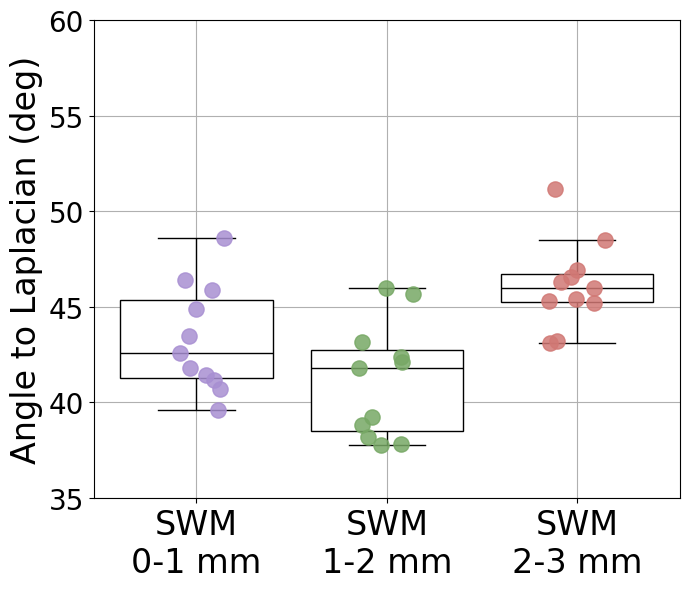

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# Step 1: Long-form dataframe
# -------------------------
df_1 = pd.DataFrame({
    'Angle': Long_L_subject_means[:, 0],
    'Depth': 'SWM\n0-1 mm'
})

df_2 = pd.DataFrame({
    'Angle': Long_L_subject_means[:, 1],
    'Depth': 'SWM\n1-2 mm'
})

df_3 = pd.DataFrame({
    'Angle': Long_L_subject_means[:, 2],
    'Depth': 'SWM\n2-3 mm'
})

df_all = pd.concat([df_1, df_2, df_3], ignore_index=True)

# -------------------------
# Step 2: Plot
# -------------------------
plt.figure(figsize=(7,6))

depth_labels = ['SWM\n0-1 mm', 'SWM\n1-2 mm', 'SWM\n2-3 mm']

sns.boxplot(
    x='Depth',
    y='Angle',
    data=df_all,
    order=depth_labels,
    linewidth=1,
    showfliers=False,
    showmeans=False,
    width=0.8,
    palette={
        'SWM\n0-1 mm': 'white',
        'SWM\n1-2 mm': 'white',
        'SWM\n2-3 mm': 'white'
    },
    #medianprops={'visible': True},
    boxprops=dict(edgecolor='black'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='black', linewidth=1)
)

# -------------------------
# Step 3: Dots
# -------------------------
dot_colors = {
    'SWM\n0-1 mm': '#A88FD2',
    'SWM\n1-2 mm': '#77A865',
    'SWM\n2-3 mm': '#D17874'
}

for i, depth in enumerate(depth_labels):

    vals = df_all[df_all['Depth'] == depth]['Angle'].values
    vals = vals[~np.isnan(vals)]

    x_jitter = i + np.random.uniform(-0.15, 0.15, len(vals))

    plt.scatter(
        x_jitter,
        vals,
        color=dot_colors[depth],
        s=120,
        alpha=0.85,
        zorder=10
    )

# -------------------------
# Step 4: Style
# -------------------------
plt.xticks(
    ticks=range(len(depth_labels)),
    labels=depth_labels,
    fontsize=24
)

plt.axhline(0, color='black', linestyle='-', linewidth=1)

plt.xlabel('', fontsize=24)
plt.ylabel('Angle to Laplacian (deg)', fontsize=24)

plt.yticks(fontsize=20)
plt.grid(True)

plt.ylim(35, 60)

plt.tight_layout()
plt.show()

Processing: PNC003_HC082

0-1 Whole = 41.41   Gyri = 37.05   Sulci = 43.95
1-2 Whole = 37.76   Gyri = 27.86   Sulci = 41.23
2-3 Whole = 43.24   Gyri = 24.26   Sulci = 47.62
Processing: PNC006_HC081

0-1 Whole = 42.58   Gyri = 34.32   Sulci = 46.48
1-2 Whole = 41.79   Gyri = 25.80   Sulci = 46.21
2-3 Whole = 48.49   Gyri = 23.30   Sulci = 53.04
Processing: PNC011_HC083

0-1 Whole = 45.90   Gyri = 37.10   Sulci = 49.84
1-2 Whole = 42.10   Gyri = 29.63   Sulci = 45.83
2-3 Whole = 45.31   Gyri = 26.56   Sulci = 49.35
Processing: PNC018_HC076

0-1 Whole = 46.42   Gyri = 35.76   Sulci = 51.41
1-2 Whole = 45.99   Gyri = 27.57   Sulci = 50.76
2-3 Whole = 51.16   Gyri = 23.88   Sulci = 55.77
Processing: PNC019_HC062

0-1 Whole = 39.60   Gyri = 33.20   Sulci = 42.97
1-2 Whole = 38.19   Gyri = 25.48   Sulci = 42.26
2-3 Whole = 45.21   Gyri = 22.99   Sulci = 49.69
Processing: PNC022_HC132

0-1 Whole = 44.87   Gyri = 36.25   Sulci = 49.22
1-2 Whole = 43.14   Gyri = 28.08   Sulci = 47.93
2-3 Whole =

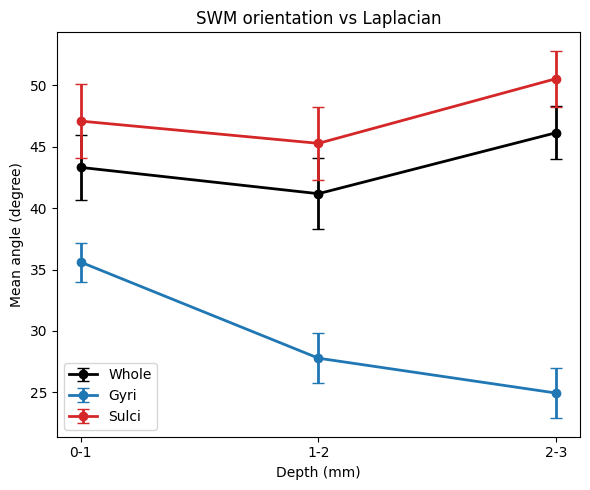

In [30]:
# ---------------------------------------------------
# paths
# ---------------------------------------------------
tract_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_prob"
lap_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd"

subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130',
    'PNC037_HC116', 'PNC038_HC140'
]

ses_dirs = ['03', '03', '03', '03', '03', '03', 'a1', 'a1', 'a1', 'a1', 'a1']

depth_bins = ["0-1", "1-2", "2-3"]
regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# store subject results
# ---------------------------------------------------
LF_left_group_results = {
    d: {r: [] for r in regions}
    for d in depth_bins
}

# ---------------------------------------------------
# subject loop
# ---------------------------------------------------
for sub, ses in zip(subject_dirs, ses_dirs):

    print("="*60)
    print("Processing:", sub)

    sub_id = sub.split("_")[0].replace("PNC", "")

    # ---------------------------------------------------
    # tract
    # ---------------------------------------------------
    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-L_space-dwi_FL-IPL_new2.tck"
    )

    track_files = glob.glob(pattern)

    if len(track_files) == 0:
        print("No tract")
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "L_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # ---------------------------------------------------
    # curvature
    # ---------------------------------------------------
    cfile = glob.glob(
        f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
        f"sub-{sub.split('_')[0]}/ses-{ses}/maps/"
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-L_surf-fsLR-32k_label-curv.func.gii"
    )[0]

    cdata = nb.load(cfile).darrays[0].data

    # ---------------------------------------------------
    # Laplacian database
    # ---------------------------------------------------
    lap_points = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    lap_dirs = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    for vidx, sl in enumerate(lap):

        if vidx >= len(cdata):
            break

        is_gyrus = cdata[vidx] < 0
        is_sulcus = cdata[vidx] > 0

        depth = 0

        for i in range(1, len(sl)-1):

            depth += np.linalg.norm(sl[i]-sl[i-1])

            if depth >= 3:
                break

            p = sl[i]

            v = sl[i+1]-sl[i-1]
            nv = np.linalg.norm(v)

            if nv == 0:
                continue

            v /= nv

            if depth < 1:
                dbin = "0-1"
            elif depth < 2:
                dbin = "1-2"
            else:
                dbin = "2-3"

            lap_points[dbin]["whole"].append(p)
            lap_dirs[dbin]["whole"].append(v)

            if is_gyrus:
                lap_points[dbin]["gyrus"].append(p)
                lap_dirs[dbin]["gyrus"].append(v)

            elif is_sulcus:
                lap_points[dbin]["sulcus"].append(p)
                lap_dirs[dbin]["sulcus"].append(v)

    # ---------------------------------------------------
    # KDTree
    # ---------------------------------------------------
    trees = {}

    for d in depth_bins:

        trees[d] = {}

        for r in regions:

            pts = np.array(lap_points[d][r])
            dirs = np.array(lap_dirs[d][r])

            if len(pts) < 10:
                trees[d][r] = None
            else:
                trees[d][r] = (cKDTree(pts), dirs)

    # ---------------------------------------------------
    # angle computation
    # ---------------------------------------------------
    subject_result = {
        d: {}
        for d in depth_bins
    }

    for d in depth_bins:

        for r in regions:

            if trees[d][r] is None:
                subject_result[d][r] = np.nan
                continue

            tree, lapdir = trees[d][r]

            angles = []

            for sl in tract:

                for i in range(1, len(sl)-1):

                    p = sl[i]

                    t = sl[i+1]-sl[i-1]

                    nt = np.linalg.norm(t)

                    if nt == 0:
                        continue

                    t /= nt

                    dist, idx = tree.query(p)

                    if dist > 1:
                        continue

                    l = lapdir[idx]

                    cosang = np.abs(np.dot(t, l))
                    cosang = np.clip(cosang, -1, 1)

                    theta = np.degrees(np.arccos(cosang))

                    angles.append(theta)

            if len(angles) == 0:
                subject_result[d][r] = np.nan
            else:
                subject_result[d][r] = np.mean(angles)

            LF_left_group_results[d][r].append(subject_result[d][r])

    print()

    for d in depth_bins:
        print(
            d,
            "Whole = %.2f   Gyri = %.2f   Sulci = %.2f"
            % (
                subject_result[d]["whole"],
                subject_result[d]["gyrus"],
                subject_result[d]["sulcus"],
            )
        )

# ---------------------------------------------------
# group statistics
# ---------------------------------------------------
print("\n")
print("="*60)
print("GROUP RESULT")
print("="*60)

group_mean = {}
group_std = {}

for r in regions:

    group_mean[r] = []
    group_std[r] = []

    print("\n", r)

    for d in depth_bins:

        vals = np.array(LF_left_group_results[d][r])

        mean = np.nanmean(vals)
        std = np.nanstd(vals)

        group_mean[r].append(mean)
        group_std[r].append(std)

        print(f"{d} mm : {mean:.2f} ± {std:.2f}")

# ---------------------------------------------------
# plot
# ---------------------------------------------------
plt.figure(figsize=(6,5))

colors = {
    "whole":"black",
    "gyrus":"tab:blue",
    "sulcus":"tab:red"
}

labels = {
    "whole":"Whole",
    "gyrus":"Gyri",
    "sulcus":"Sulci"
}

x = np.arange(3)

for r in regions:

    plt.errorbar(
        x,
        group_mean[r],
        yerr=group_std[r],
        marker='o',
        linewidth=2,
        capsize=4,
        label=labels[r],
        color=colors[r]
    )

plt.xticks(x, ["0-1","1-2","2-3"])
plt.xlabel("Depth (mm)")
plt.ylabel("Mean angle (degree)")
plt.title("SWM orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

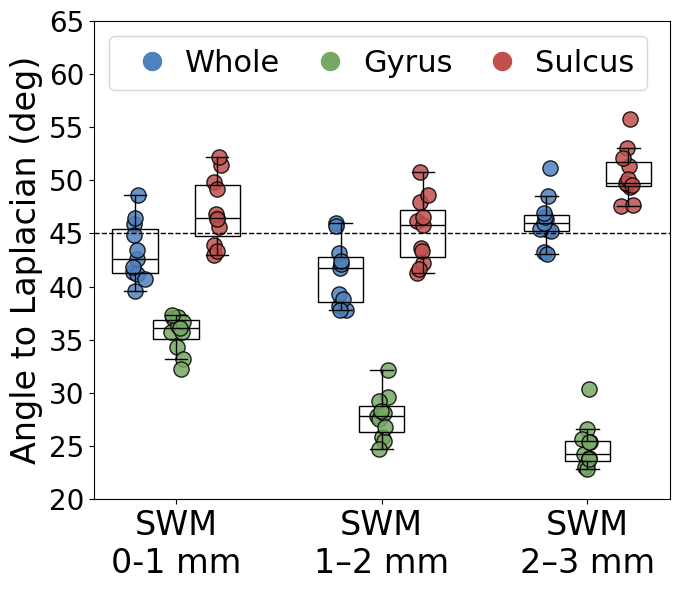

In [83]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "whole": "#4F81BD",
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 0,
    "1-2": 2.5,
    "2-3": 5
}

offsets = {
    "whole": -0.5,
    "gyrus": 0.0,
    "sulcus": 0.5
}

width = 0.55

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(LF_left_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([0, 2.5, 5])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(45, color="black", linestyle="--", linewidth=1)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#4F81BD', markersize=15,
               label='Whole'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

#ax.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=16)
ax.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

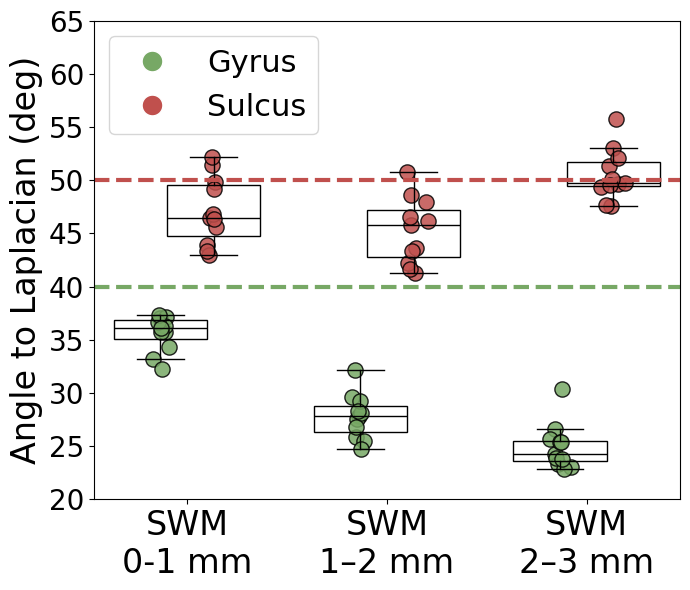

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 1,
    "1-2": 2.5,
    "2-3": 4
}

offsets = {
    "gyrus": -0.2,
    "sulcus": 0.2
}

width = 0.7

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(LF_left_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([1, 2.5, 4])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(50, color="#C0504D", linestyle="--", linewidth=3)
ax.axhline(40, color="#77A865", linestyle="--", linewidth=3)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

ax.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=22)
#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

### Long-range fiber (right)


Processing: PNC003_HC082
  mean angle (0–1 mm) = 41.62
  mean angle (1–2 mm) = 37.67
  mean angle (2–3 mm) = 46.74

Processing: PNC006_HC081
  mean angle (0–1 mm) = 46.37
  mean angle (1–2 mm) = 45.79
  mean angle (2–3 mm) = 51.10

Processing: PNC011_HC083
  mean angle (0–1 mm) = 41.87
  mean angle (1–2 mm) = 37.21
  mean angle (2–3 mm) = 41.38

Processing: PNC018_HC076
  mean angle (0–1 mm) = 43.52
  mean angle (1–2 mm) = 45.88
  mean angle (2–3 mm) = 52.01

Processing: PNC019_HC062
  mean angle (0–1 mm) = 42.23
  mean angle (1–2 mm) = 38.42
  mean angle (2–3 mm) = 42.94

Processing: PNC022_HC132
  mean angle (0–1 mm) = 45.16
  mean angle (1–2 mm) = 43.06
  mean angle (2–3 mm) = 46.77

Processing: PNC024_HC088
  mean angle (0–1 mm) = 45.75
  mean angle (1–2 mm) = 43.69
  mean angle (2–3 mm) = 49.09

Processing: PNC025_HC128
  mean angle (0–1 mm) = 43.90
  mean angle (1–2 mm) = 43.42
  mean angle (2–3 mm) = 47.79

Processing: PNC026_HC130
  mean angle (0–1 mm) = 46.35
  mean angle (1–

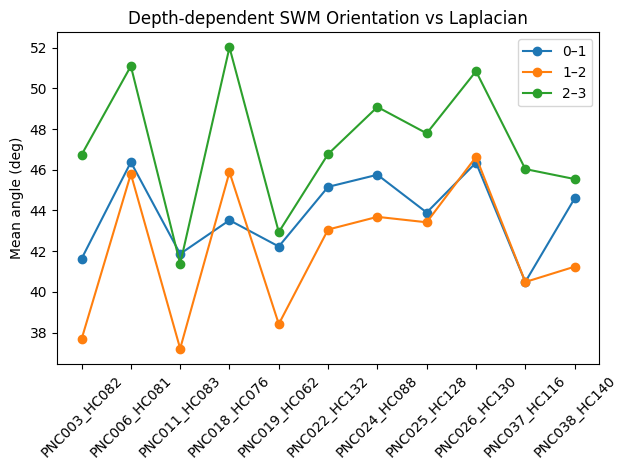

In [85]:
# -------------------------
# store results
# -------------------------
Long_R_subject_means = []   # each subject: [0-1, 1-2, 2-3]

# -------------------------
# loop subjects
# -------------------------
for sub in subject_dirs:

    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-*_hemi-R_space-dwi_FL-IPL_new2.tck"
    )

    track_files = glob.glob(pattern)
    if len(track_files) == 0:
        print("No tract file:", sub)
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "R_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    print("\nProcessing:", sub)

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # -------------------------
    # build Laplacian depth bins
    # -------------------------
    lap_points_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }
    lap_dirs_bins = {
        "0-1": [], "1-2": [], "2-3": []
    }

    for sl in lap:

        depth = 0.0

        for i in range(1, len(sl)-1):

            seg = np.linalg.norm(sl[i] - sl[i-1])
            depth += seg

            p = sl[i]

            v = sl[i+1] - sl[i-1]
            nv = np.linalg.norm(v)
            if nv == 0:
                continue
            v = v / nv

            if depth < 1.0:
                lap_points_bins["0-1"].append(p)
                lap_dirs_bins["0-1"].append(v)

            elif depth < 2.0:
                lap_points_bins["1-2"].append(p)
                lap_dirs_bins["1-2"].append(v)

            elif depth < 3.0:
                lap_points_bins["2-3"].append(p)
                lap_dirs_bins["2-3"].append(v)

            else:
                break

    # convert to arrays + trees
    trees = {}
    for k in lap_points_bins:

        pts = np.array(lap_points_bins[k])
        dirs = np.array(lap_dirs_bins[k])

        if len(pts) < 10:
            trees[k] = None
        else:
            trees[k] = (cKDTree(pts), dirs)

    # -------------------------
    # compute angles per depth
    # -------------------------
    subject_result = []

    for depth_bin in ["0-1", "1-2", "2-3"]:

        if trees[depth_bin] is None:
            subject_result.append(np.nan)
            continue

        tree, lap_dirs = trees[depth_bin]

        angles = []

        for sl in tract:

            for i in range(1, len(sl)-1):

                p = sl[i]

                t = sl[i+1] - sl[i-1]
                nt = np.linalg.norm(t)
                if nt == 0:
                    continue
                t = t / nt

                dist, idx = tree.query(p, k=1)

                if dist > 1.0:
                    continue

                l = lap_dirs[idx]

                cosang = np.abs(np.dot(t, l))
                cosang = np.clip(cosang, -1, 1)

                theta = np.degrees(np.arccos(cosang))
                angles.append(theta)

        angles = np.array(angles)

        if len(angles) == 0:
            subject_result.append(np.nan)
        else:
            subject_result.append(np.mean(angles))

    Long_R_subject_means.append(subject_result)

    print(f"  mean angle (0–1 mm) = {subject_result[0]:.2f}")
    print(f"  mean angle (1–2 mm) = {subject_result[1]:.2f}")
    print(f"  mean angle (2–3 mm) = {subject_result[2]:.2f}")

# -------------------------
# group statistics
# -------------------------
Long_R_subject_means = np.array(Long_R_subject_means)

print("\n===== GROUP RESULT =====")

for i, label in enumerate(["0–1 mm", "1–2 mm", "2–3 mm"]):
    vals = Long_R_subject_means[:, i]
    print(f"{label}: {np.nanmean(vals):.2f} ± {np.nanstd(vals):.2f}")

# -------------------------
# plot
# -------------------------
plt.figure()

x = np.arange(len(subject_dirs))
for i, label in enumerate(["0–1", "1–2", "2–3"]):
    plt.plot(x, Long_R_subject_means[:, i], marker='o', label=label)

plt.xticks(x, subject_dirs, rotation=45)
plt.ylabel("Mean angle (deg)")
plt.title("Depth-dependent SWM Orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_2045607/663391953.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


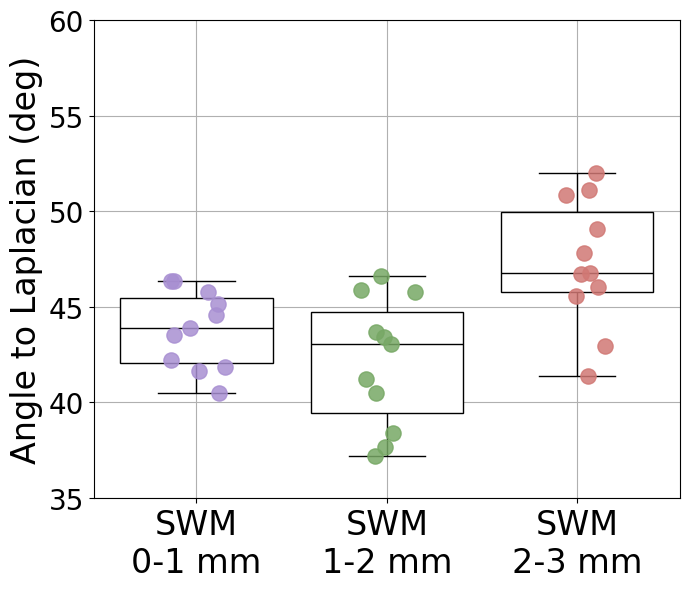

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# Step 1: Long-form dataframe
# -------------------------
df_1 = pd.DataFrame({
    'Angle': Long_R_subject_means[:, 0],
    'Depth': 'SWM\n0-1 mm'
})

df_2 = pd.DataFrame({
    'Angle': Long_R_subject_means[:, 1],
    'Depth': 'SWM\n1-2 mm'
})

df_3 = pd.DataFrame({
    'Angle': Long_R_subject_means[:, 2],
    'Depth': 'SWM\n2-3 mm'
})

df_all = pd.concat([df_1, df_2, df_3], ignore_index=True)

# -------------------------
# Step 2: Plot
# -------------------------
plt.figure(figsize=(7,6))

depth_labels = ['SWM\n0-1 mm', 'SWM\n1-2 mm', 'SWM\n2-3 mm']

sns.boxplot(
    x='Depth',
    y='Angle',
    data=df_all,
    order=depth_labels,
    linewidth=1,
    showfliers=False,
    showmeans=False,
    width=0.8,
    palette={
        'SWM\n0-1 mm': 'white',
        'SWM\n1-2 mm': 'white',
        'SWM\n2-3 mm': 'white'
    },
    #medianprops={'visible': True},
    boxprops=dict(edgecolor='black'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='black', linewidth=1)
)

# -------------------------
# Step 3: Dots
# -------------------------
dot_colors = {
    'SWM\n0-1 mm': '#A88FD2',
    'SWM\n1-2 mm': '#77A865',
    'SWM\n2-3 mm': '#D17874'
}

for i, depth in enumerate(depth_labels):

    vals = df_all[df_all['Depth'] == depth]['Angle'].values
    vals = vals[~np.isnan(vals)]

    x_jitter = i + np.random.uniform(-0.15, 0.15, len(vals))

    plt.scatter(
        x_jitter,
        vals,
        color=dot_colors[depth],
        s=120,
        alpha=0.85,
        zorder=10
    )

# -------------------------
# Step 4: Style
# -------------------------
plt.xticks(
    ticks=range(len(depth_labels)),
    labels=depth_labels,
    fontsize=24
)

plt.axhline(0, color='black', linestyle='-', linewidth=1)

plt.xlabel('', fontsize=24)
plt.ylabel('Angle to Laplacian (deg)', fontsize=24)

plt.yticks(fontsize=20)
plt.grid(True)

plt.ylim(35, 60)

plt.tight_layout()
plt.show()

Processing: PNC003_HC082

0-1 Whole = 41.62   Gyri = 34.09   Sulci = 45.17
1-2 Whole = 37.67   Gyri = 26.90   Sulci = 41.42
2-3 Whole = 46.74   Gyri = 24.36   Sulci = 51.58
Processing: PNC006_HC081

0-1 Whole = 46.37   Gyri = 38.87   Sulci = 49.74
1-2 Whole = 45.79   Gyri = 30.07   Sulci = 50.33
2-3 Whole = 51.10   Gyri = 26.23   Sulci = 56.20
Processing: PNC011_HC083

0-1 Whole = 41.87   Gyri = 38.16   Sulci = 44.15
1-2 Whole = 37.21   Gyri = 30.10   Sulci = 40.05
2-3 Whole = 41.38   Gyri = 26.75   Sulci = 45.26
Processing: PNC018_HC076

0-1 Whole = 43.52   Gyri = 35.85   Sulci = 47.62
1-2 Whole = 45.88   Gyri = 28.94   Sulci = 50.94
2-3 Whole = 52.01   Gyri = 26.78   Sulci = 56.92
Processing: PNC019_HC062

0-1 Whole = 42.23   Gyri = 36.69   Sulci = 45.07
1-2 Whole = 38.42   Gyri = 27.29   Sulci = 42.22
2-3 Whole = 42.94   Gyri = 23.64   Sulci = 47.47
Processing: PNC022_HC132

0-1 Whole = 45.16   Gyri = 35.58   Sulci = 50.63
1-2 Whole = 43.06   Gyri = 30.97   Sulci = 47.76
2-3 Whole =

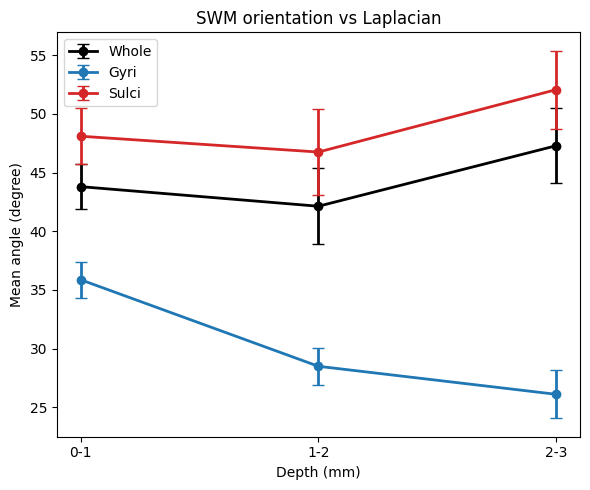

In [35]:
# ---------------------------------------------------
# paths
# ---------------------------------------------------
tract_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/validation_prob"
lap_dir = "/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd"

subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083',
    'PNC018_HC076', 'PNC019_HC062', 'PNC022_HC132',
    'PNC024_HC088', 'PNC025_HC128', 'PNC026_HC130',
    'PNC037_HC116', 'PNC038_HC140'
]

ses_dirs = ['03', '03', '03', '03', '03', '03', 'a1', 'a1', 'a1', 'a1', 'a1']

depth_bins = ["0-1", "1-2", "2-3"]
regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# store subject results
# ---------------------------------------------------
LF_right_group_results = {
    d: {r: [] for r in regions}
    for d in depth_bins
}

# ---------------------------------------------------
# subject loop
# ---------------------------------------------------
for sub, ses in zip(subject_dirs, ses_dirs):

    print("="*60)
    print("Processing:", sub)

    sub_id = sub.split("_")[0].replace("PNC", "")

    # ---------------------------------------------------
    # tract
    # ---------------------------------------------------
    pattern = os.path.join(
        tract_dir,
        sub,
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-R_space-dwi_FL-IPL_new2.tck"
    )

    track_files = glob.glob(pattern)

    if len(track_files) == 0:
        print("No tract")
        continue

    tract_path = track_files[0]

    lap_path = os.path.join(
        lap_dir,
        sub,
        "R_fsLR32k-laplace-wm-streamlines_dwispace.tck"
    )

    tract = load(tract_path).streamlines
    lap = load(lap_path).streamlines

    # ---------------------------------------------------
    # curvature
    # ---------------------------------------------------
    cfile = glob.glob(
        f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
        f"sub-{sub.split('_')[0]}/ses-{ses}/maps/"
        f"sub-{sub.split('_')[0]}_ses-{ses}_hemi-R_surf-fsLR-32k_label-curv.func.gii"
    )[0]

    cdata = nb.load(cfile).darrays[0].data

    # ---------------------------------------------------
    # Laplacian database
    # ---------------------------------------------------
    lap_points = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    lap_dirs = {
        d: {r: [] for r in regions}
        for d in depth_bins
    }

    for vidx, sl in enumerate(lap):

        if vidx >= len(cdata):
            break

        is_gyrus = cdata[vidx] < 0
        is_sulcus = cdata[vidx] > 0

        depth = 0

        for i in range(1, len(sl)-1):

            depth += np.linalg.norm(sl[i]-sl[i-1])

            if depth >= 3:
                break

            p = sl[i]

            v = sl[i+1]-sl[i-1]
            nv = np.linalg.norm(v)

            if nv == 0:
                continue

            v /= nv

            if depth < 1:
                dbin = "0-1"
            elif depth < 2:
                dbin = "1-2"
            else:
                dbin = "2-3"

            lap_points[dbin]["whole"].append(p)
            lap_dirs[dbin]["whole"].append(v)

            if is_gyrus:
                lap_points[dbin]["gyrus"].append(p)
                lap_dirs[dbin]["gyrus"].append(v)

            elif is_sulcus:
                lap_points[dbin]["sulcus"].append(p)
                lap_dirs[dbin]["sulcus"].append(v)

    # ---------------------------------------------------
    # KDTree
    # ---------------------------------------------------
    trees = {}

    for d in depth_bins:

        trees[d] = {}

        for r in regions:

            pts = np.array(lap_points[d][r])
            dirs = np.array(lap_dirs[d][r])

            if len(pts) < 10:
                trees[d][r] = None
            else:
                trees[d][r] = (cKDTree(pts), dirs)

    # ---------------------------------------------------
    # angle computation
    # ---------------------------------------------------
    subject_result = {
        d: {}
        for d in depth_bins
    }

    for d in depth_bins:

        for r in regions:

            if trees[d][r] is None:
                subject_result[d][r] = np.nan
                continue

            tree, lapdir = trees[d][r]

            angles = []

            for sl in tract:

                for i in range(1, len(sl)-1):

                    p = sl[i]

                    t = sl[i+1]-sl[i-1]

                    nt = np.linalg.norm(t)

                    if nt == 0:
                        continue

                    t /= nt

                    dist, idx = tree.query(p)

                    if dist > 1:
                        continue

                    l = lapdir[idx]

                    cosang = np.abs(np.dot(t, l))
                    cosang = np.clip(cosang, -1, 1)

                    theta = np.degrees(np.arccos(cosang))

                    angles.append(theta)

            if len(angles) == 0:
                subject_result[d][r] = np.nan
            else:
                subject_result[d][r] = np.mean(angles)

            LF_right_group_results[d][r].append(subject_result[d][r])

    print()

    for d in depth_bins:
        print(
            d,
            "Whole = %.2f   Gyri = %.2f   Sulci = %.2f"
            % (
                subject_result[d]["whole"],
                subject_result[d]["gyrus"],
                subject_result[d]["sulcus"],
            )
        )

# ---------------------------------------------------
# group statistics
# ---------------------------------------------------
print("\n")
print("="*60)
print("GROUP RESULT")
print("="*60)

group_mean = {}
group_std = {}

for r in regions:

    group_mean[r] = []
    group_std[r] = []

    print("\n", r)

    for d in depth_bins:

        vals = np.array(LF_right_group_results[d][r])

        mean = np.nanmean(vals)
        std = np.nanstd(vals)

        group_mean[r].append(mean)
        group_std[r].append(std)

        print(f"{d} mm : {mean:.2f} ± {std:.2f}")

# ---------------------------------------------------
# plot
# ---------------------------------------------------
plt.figure(figsize=(6,5))

colors = {
    "whole":"black",
    "gyrus":"tab:blue",
    "sulcus":"tab:red"
}

labels = {
    "whole":"Whole",
    "gyrus":"Gyri",
    "sulcus":"Sulci"
}

x = np.arange(3)

for r in regions:

    plt.errorbar(
        x,
        group_mean[r],
        yerr=group_std[r],
        marker='o',
        linewidth=2,
        capsize=4,
        label=labels[r],
        color=colors[r]
    )

plt.xticks(x, ["0-1","1-2","2-3"])
plt.xlabel("Depth (mm)")
plt.ylabel("Mean angle (degree)")
plt.title("SWM orientation vs Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

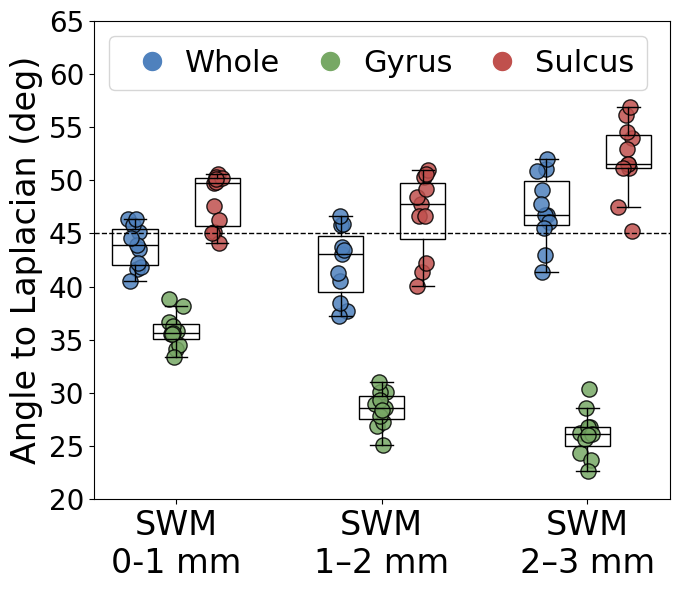

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "whole": "#4F81BD",
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["whole", "gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 0,
    "1-2": 2.5,
    "2-3": 5
}

offsets = {
    "whole": -0.5,
    "gyrus": 0.0,
    "sulcus": 0.5
}

width = 0.55

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(LF_right_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([0, 2.5, 5])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(45, color="black", linestyle="--", linewidth=1)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#4F81BD', markersize=15,
               label='Whole'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

ax.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

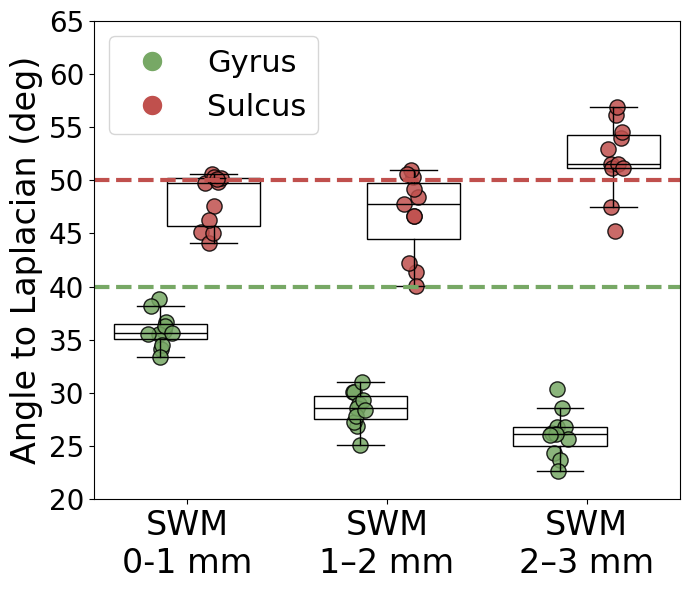

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# setup
# ---------------------------------------------------
depth_bins = ["0-1", "1-2", "2-3"]

colors = {
    "gyrus": "#77A865",
    "sulcus": "#C0504D"
}

regions = ["gyrus", "sulcus"]

# ---------------------------------------------------
# x positions (grouped layout like your example)
# ---------------------------------------------------
base_positions = {
    "0-1": 1,
    "1-2": 2.5,
    "2-3": 4
}

offsets = {
    "gyrus": -0.2,
    "sulcus": 0.2
}

width = 0.7

# ---------------------------------------------------
# figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7,6))

all_data = []
all_pos = []

# ---------------------------------------------------
# BOXPLOT (manual positions)
# ---------------------------------------------------
for d in depth_bins:
    for r in regions:

        vals = np.array(LF_right_group_results[d][r])
        vals = vals[~np.isnan(vals)]

        pos = base_positions[d] + offsets[r]

        # boxplot
        ax.boxplot(
            vals,
            positions=[pos],
            widths=width,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(color="black", facecolor="none"),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black")
        )

        # scatter (jitter)
        jitter = np.random.normal(pos, 0.04, size=len(vals))

        ax.scatter(
            jitter,
            vals,
            color=colors[r],
            edgecolor="black",
            s=120,
            alpha=0.85
        )

# ---------------------------------------------------
# x-axis formatting
# ---------------------------------------------------
ax.set_xticks([1, 2.5, 4])
ax.set_xticklabels(["SWM\n0-1 mm", "SWM\n1–2 mm", "SWM\n2–3 mm"], fontsize=24)

plt.yticks(fontsize=20)
plt.ylim(20, 65)
#plt.grid(True)
ax.set_ylabel("Angle to Laplacian (deg)", fontsize=24)
#ax.set_title("SWM orientation vs Laplacian depth", fontsize=14)

ax.axhline(50, color="#C0504D", linestyle="--", linewidth=3)
ax.axhline(40, color="#77A865", linestyle="--", linewidth=3)

# ---------------------------------------------------
# legend (exact style you requested)
# ---------------------------------------------------
legend_patches = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#77A865', markersize=15,
               label='Gyrus'),

    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C0504D', markersize=15,
               label='Sulcus'),
]

ax.legend(handles=legend_patches, loc="upper left", frameon=True, fontsize=22)
#ax.legend(handles=legend_patches, loc="lower left", frameon=True, fontsize=22, ncol=3, columnspacing=0.6, handletextpad=0.1)

# ---------------------------------------------------
plt.tight_layout()
plt.show()

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_two_boxplots(values1, values2,
                      labels=['Group 1', 'Group 2']):

    # DataFrame (long format)
    df = pd.DataFrame({
        'Value': np.concatenate([values1, values2]),
        'Group': ([labels[0]] * len(values1)) + ([labels[1]] * len(values2))
    })

    plt.figure(figsize=(8, 6))

    # boxplot
    sns.boxplot(
        x='Group',
        y='Value',
        data=df,
        linewidth=3,
        showfliers=False,
        showmeans=False,
        palette={labels[0]: 'white',
                 labels[1]: 'white'},
        width=0.6,
        medianprops={'visible': True}
    )

    # scatter points
    colors = ['#E6C84A', '#8BC34A']

    for i, values in enumerate([values1, values2]):

        values = np.array(values)

        x_jitter = np.random.uniform(
            i - 0.1,
            i + 0.1,
            len(values)
        )

        plt.scatter(
            x_jitter,
            values,
            color=colors[i],
            s=150,
            alpha=0.8,
            zorder=10
        )

    # y-axis
    plt.axhline(0, color='black', linewidth=1)

    plt.xlabel('')
    plt.ylabel('Percentage (%)', fontsize=20)

    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)

    # percentage range
    plt.ylim(0, 110)

    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [61]:
t1_percent = [90.5, 89, 80.2, 97.2, 77.8, 79.3, 75.9, 89.2]
t2_percent = [83.1, 86.6, 85.7, 58.6, 46.2, 54, 43.8, 77.2, 95, 70.8, 73.2, 70.5, 53.1, 51.3, 85.9, 84, 34.2, 63.5, 59.1, 65.7, 100, 100]

/tmp/ipykernel_23193/1400381208.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


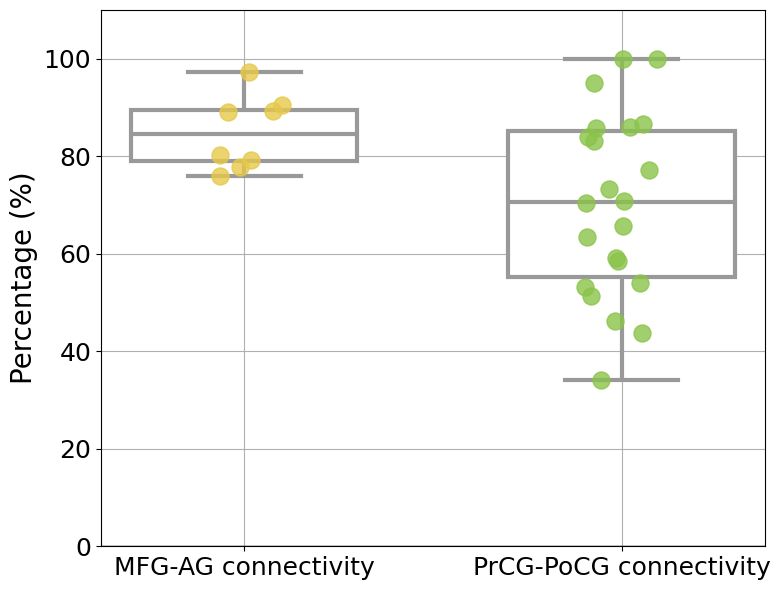

In [67]:
plot_two_boxplots(values1=t1_percent, values2=t2_percent, labels=['MFG-AG connectivity', 'PrCG-PoCG connectivity'])